## Read embeddings

In [107]:
import scanpy as sc



In [108]:
import anndata as ad

In [109]:
import numpy as np

In [118]:
import pandas as pd
import pandas as pd
# MODELS PARAMS
## PARAMETERS
RUNS = 20
total_splits = 1

MODELS_DESCRIPTIONS = {
           "class_I_simple_clustering": {
        "path": "experiment_results/paper2_core_clustering/reconstructed_models/",
        "states": 15,
        "params_string": "60-min_iters-4-aaas",
        "combination_size": 2,
        "alleles": [
                # 'HLA-DRB1*01:01'
                    'HLA-A*01:01',
                    'HLA-A*03:01'
                    ],
        "target_lengths": [8, 9,10, 11, 12,13, 14],
        "core_start_state": [15,16],
        "core_end_state": [17,18],
        "need_to_delete": [],
        "skip_states": [],

    },
                   "class_I_simple_clustering_simulated": {
        "path": "experiment_results/paper2_core_clustering/reconstructed_models/",
        "states": 15,
        "params_string": "60-min_iters-4-aaas",
        "combination_size":1,
        "alleles": [
             "dummy_allele"
                # 'HLA-DRB1*01:01'

                    ],
        "target_lengths": [ 9,10, 11],
        "core_start_state": [15,16],
        "core_end_state": [17,18],
        "need_to_delete": [],
        "skip_states": [],

    },
    
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

# selected_model = MODELS_DESCRIPTIONS["multiple_allele_imbalanced"]
# selected_model = MODELS_DESCRIPTIONS["multiple_allele_balanced"]
# selected_model = MODELS_DESCRIPTIONS["single_allele_imbalanced"]
# selected_model = MODELS_DESCRIPTIONS["single_allele_balanced"]
selected_model = MODELS_DESCRIPTIONS["class_I_simple_clustering_simulated"]

models_to_read = {"v"}

In [119]:
#Selected combination
# combination = ('HLA-A*01:01', 'HLA-A*02:01')
#combination = ('HLA-A*01:01', 'HLA-A*03:01')
combination = ('dummy_allele',)
# combination = ('HLA-A*02:01', 'HLA-A*03:01')
# combination = ('HLA-A*01:01','HLA-A*02:01', 'HLA-A*03:01')

# combination = ('HLA-A*01:01',)
# combination = ('HLA-A*03:01',)
# combination = ('HLA-A*02:01',)
# combination = ('HLA-DRB1*01:01', 'HLA-DPA1*01:03/DPB1*04:01')
# combination = ('HLA-DRB1*01:01',)
#combination = ('HLA-DQA1*05:01/DQB1*02:01',)

In [120]:
combination

('dummy_allele',)

In [121]:
for allele_name in combination:
    assert allele_name in selected_model['alleles'], f"{allele_name} not in "
selected_alleles = list(combination)


states = selected_model['states']
TARGET_LENGTHS = selected_model['target_lengths']
selected_combination = "+".join(sorted(selected_alleles)).replace('-', '_').replace('*', '_').replace(':', '_').replace('/', '_')
selected_model_split = 0 # should match to data split (if original train/test used) in order to have true test case
selected_model_run = "combined"
target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])

In [122]:
mixed_model_bw =f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'
mixed_model_bwv = f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}_plus_viterbi'
mixed_model_v = f'{selected_model_run}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'


name_to_model_root = dict()
name_to_model_root[mixed_model_bw] = selected_model['path']
name_to_model_root[mixed_model_bwv] = selected_model['path']
name_to_model_root[mixed_model_v] = selected_model['path']

In [123]:
def load_embeddings(model):
    print(f"model {model}")
    TARGET_PATH_TO_FILES = name_to_model_root[model] + model
    # Train 
    train_df =  pd.read_csv("{}/train_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)
    # Test
    test_df = None
    # test_df =  pd.read_csv("{}/test_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)

    # paths_df['path'] = paths_df['path'].apply(pd.eval)
    # paths_df['path'] = paths_df['path'].astype(list)
    return  train_df, test_df


In [124]:
%%time
per_model_type_train_embeddings = dict()
per_model_type_test_embeddings = dict()
# # BW
if "bw" in models_to_read:
    train_df, test_df = load_embeddings(mixed_model_bw)
    per_model_type_train_embeddings['bw'] = train_df
    # per_model_type_test_embeddings['bw'] = test_df
# # BWV
if "bwv" in models_to_read:
    train_df, test_df = load_embeddings(mixed_model_bwv)
    per_model_type_train_embeddings['bwv'] = train_df
    # per_model_type_test_embeddings['bwv'] = test_df
# V
if "v" in models_to_read:
    train_df, test_df = load_embeddings(mixed_model_v)
    per_model_type_train_embeddings['v'] = train_df
    # per_model_type_test_embeddings['v'] = test_df

model combined_run-9-10-11-15-st-viterbi-alg-5-min_iters_model-dummy_allele-0
CPU times: total: 28.5 s
Wall time: 28.5 s


In [125]:
train_df.allele.value_counts()

Dummy_allele_8    2958
Dummy_allele_7    2405
Dummy_allele_5    1269
Dummy_allele_3    1224
Dummy_allele_6    1210
Dummy_allele_4    1175
Dummy_allele_2     617
Dummy_allele_0     580
Dummy_allele_1     561
Name: allele, dtype: int64

In [126]:
import seaborn as sns

# Scanpy

In [127]:
target_df = per_model_type_train_embeddings['v'].copy()


In [128]:
target_df

,0,1,2,3,4,5,6,7,8,9,...,9992,9993,9994,9995,9996,9997,9998,9999,allele,peptide
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Dummy_allele_4,FDGIKYEERL
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Dummy_allele_4,FWWLKQYRRL
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Dummy_allele_4,VSHLMDETYL
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Dummy_allele_4,FWNPKMEMTV
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Dummy_allele_5,VMHVSKTWFQ
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11994,NaN,-35.036187,-44.101359,-30.628897,-31.167951,-34.994206,-38.705498,-42.726981,-38.775937,-33.976056,...,NaN,NaN,-32.669488,NaN,NaN,NaN,NaN,-31.36065,Dummy_allele_8,FRQTAHNPL
11995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,-43.106045,NaN,NaN,NaN,Dummy_allele_2,FARSLHTEFCN
11996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Dummy_allele_5,VFHKTFGRLN
11997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Dummy_allele_5,VTKRDKGSEQ


In [129]:
target_df['peptide'].str.len().value_counts()

9     6573
10    3668
11    1758
Name: peptide, dtype: int64

## Select target df for analysis

In [130]:
TARGET_LENGTH = 9


target_df = target_df[target_df.peptide.str.len() == TARGET_LENGTH]

In [131]:
target_df

,0,1,2,3,4,5,6,7,8,9,...,9992,9993,9994,9995,9996,9997,9998,9999,allele,peptide
5,NaN,-33.589726,-32.804547,-29.382308,-38.836464,-32.057075,-25.078257,-35.879710,-36.025140,-32.923047,...,NaN,NaN,-35.017644,NaN,NaN,NaN,NaN,-48.261902,Dummy_allele_7,VPVKQIGEQ
6,NaN,-43.555957,-33.345235,-39.838340,-48.280282,-25.212543,-38.648253,-33.489293,-29.835659,-39.233523,...,NaN,NaN,-43.459457,NaN,NaN,NaN,NaN,-40.096782,Dummy_allele_6,LDWWCESHV
8,NaN,-38.949646,-38.410877,-34.542356,-35.509570,-33.400199,-48.096759,-38.432839,-42.820539,-29.456792,...,NaN,NaN,-24.919498,NaN,NaN,NaN,NaN,-31.425436,Dummy_allele_8,LTPTNHKCL
9,NaN,-37.210997,-27.845001,-33.003579,-42.457735,-27.097530,-36.701280,-31.266012,-31.411442,-32.385407,...,NaN,NaN,-38.135731,NaN,NaN,NaN,NaN,-40.433350,Dummy_allele_7,WIVKQTGCQ
10,NaN,-48.157088,-37.946366,-43.288117,-44.704484,-28.128454,-39.719356,-38.379772,-34.179650,-42.669914,...,NaN,NaN,-44.146679,NaN,NaN,NaN,NaN,-30.761896,Dummy_allele_8,LWEIDQIVV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11989,NaN,-22.532338,-21.940679,-27.689502,-27.256662,-30.557790,-21.792028,-24.822322,-24.967752,-31.230241,...,NaN,NaN,-25.181762,NaN,NaN,NaN,NaN,-38.478646,Dummy_allele_7,FPVRYCSDQ
11991,NaN,-27.024302,-26.239123,-32.181467,-32.271040,-34.823696,-18.355242,-29.281748,-29.427178,-35.722205,...,NaN,NaN,-38.702809,NaN,NaN,NaN,NaN,-41.017931,Dummy_allele_7,VPSRRGGWQ
11992,NaN,-34.102303,-43.167476,-29.894885,-38.826628,-34.011116,-34.345807,-33.491191,-29.291069,-29.276713,...,NaN,NaN,-35.363371,NaN,NaN,NaN,NaN,-34.491791,Dummy_allele_6,FNEKIYSFL
11993,NaN,-20.415107,-29.480279,-25.041597,-25.661845,-37.566716,-29.466741,-23.867330,-24.012760,-24.423425,...,NaN,NaN,-31.101494,NaN,NaN,NaN,NaN,-39.239458,Dummy_allele_8,FNVSRKGRL


In [132]:
# ##

# target_df = target_df.loc[filtered_peptides]
# ##

### Filter empty columns

In [133]:
target_df.replace([-np.inf], np.nan, inplace=True)
target_df = target_df.dropna(axis=1, how='all').copy()

C:\Users\denkl\AppData\Local\Temp\ipykernel_16804\3115981495.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  target_df.replace([-np.inf], np.nan, inplace=True)


In [134]:
target_df

,1,2,3,4,5,6,7,8,9,10,...,9974,9978,9983,9987,9989,9991,9994,9999,allele,peptide
5,-33.589726,-32.804547,-29.382308,-38.836464,-32.057075,-25.078257,-35.879710,-36.025140,-32.923047,-28.597129,...,-42.692282,-43.592213,-42.868180,-43.208135,-35.150638,-44.852251,-35.017644,-48.261902,Dummy_allele_7,VPVKQIGEQ
6,-43.555957,-33.345235,-39.838340,-48.280282,-25.212543,-38.648253,-33.489293,-29.835659,-39.233523,-29.627618,...,-36.442903,-41.927532,-43.599777,-45.303143,-37.340800,-36.478145,-43.459457,-40.096782,Dummy_allele_6,LDWWCESHV
8,-38.949646,-38.410877,-34.542356,-35.509570,-33.400199,-48.096759,-38.432839,-42.820539,-29.456792,-34.003587,...,-37.057169,-39.493548,-31.276504,-45.091998,-29.387873,-37.092411,-24.919498,-31.425436,Dummy_allele_8,LTPTNHKCL
9,-37.210997,-27.845001,-33.003579,-42.457735,-27.097530,-36.701280,-31.266012,-31.411442,-32.385407,-23.637583,...,-44.833414,-39.125143,-39.087462,-38.881389,-40.604487,-46.993382,-38.135731,-40.433350,Dummy_allele_7,WIVKQTGCQ
10,-48.157088,-37.946366,-43.288117,-44.704484,-28.128454,-39.719356,-38.379772,-34.179650,-42.669914,-33.077395,...,-48.518472,-37.460139,-21.761511,-40.634603,-45.647221,-48.553715,-44.146679,-30.761896,Dummy_allele_8,LWEIDQIVV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11989,-22.532338,-21.940679,-27.689502,-27.256662,-30.557790,-21.792028,-24.822322,-24.967752,-31.230241,-27.097843,...,-31.019780,-33.869525,-34.604476,-43.264124,-35.564589,-34.613731,-25.181762,-38.478646,Dummy_allele_7,FPVRYCSDQ
11991,-27.024302,-26.239123,-32.181467,-32.271040,-34.823696,-18.355242,-29.281748,-29.427178,-35.722205,-31.396287,...,-35.018070,-40.719921,-39.899318,-34.615641,-33.294594,-39.091442,-38.702809,-41.017931,Dummy_allele_7,VPSRRGGWQ
11992,-34.102303,-43.167476,-29.894885,-38.826628,-34.011116,-34.345807,-33.491191,-29.291069,-29.276713,-38.960057,...,-46.430071,-36.965994,-30.269271,-45.295920,-40.730228,-43.068313,-35.363371,-34.491791,Dummy_allele_6,FNEKIYSFL
11993,-20.415107,-29.480279,-25.041597,-25.661845,-37.566716,-29.466741,-23.867330,-24.012760,-24.423425,-34.106769,...,-39.211311,-36.542211,-33.845490,-36.211430,-39.574555,-43.284683,-31.101494,-39.239458,Dummy_allele_8,FNVSRKGRL


In [135]:
target_df.index = target_df['peptide'].values

In [136]:
dropped_columns = target_df.drop(columns=['allele', 'peptide']).copy()
transposed = dropped_columns.T.copy()

In [137]:
target_df['allele'].value_counts()

Dummy_allele_8    2958
Dummy_allele_7    2405
Dummy_allele_6    1210
Name: allele, dtype: int64

In [138]:
target_df.shape

(6573, 5083)

In [139]:
# target_df = target_df.loc[:, list(map(str,np.arange(0, 1000))) + ['allele', 'peptide']]

## Code to deal with missing values

In [140]:


# from sklearn.experimental import enable_iterative_imputer
# from sklearn.impute import IterativeImputer
# imp = IterativeImputer(max_iter=10, random_state=0, verbose=2)
# X = np.exp(target_df.drop(columns=['allele', 'peptide']).values)
# X = imp.fit_transform(X)

In [141]:
## Try log prob normalization 

In [142]:
## Was trying to normalize logprobs to see as (from 0 to 1)
# maximums = np.nanmax(X, axis=0)
# X_converted = np.exp(X - maximums)
# sums = np.nansum(np.sort(X_converted, axis=0), axis=0)
# X_converted = X_converted / sums


In [143]:
# from sklearn.impute import SimpleImputer
# imp_mean = SimpleImputer(missing_values=np.nan, strategy='mean')

# X = -target_df.drop(columns=['allele', 'peptide']).values
# # X = np.exp(target_df.drop(columns=['allele', 'peptide']).values)
# X = imp_mean.fit_transform(X)

# DO Scanpy

In [144]:
obs = pd.DataFrame({"peptide": target_df.index.values, "allele": target_df['allele'].values, "length": target_df.index.str.len().values})
var = pd.DataFrame({"path":target_df.columns.drop(['allele', 'peptide'])})
# X = np.exp(target_df.drop(columns=['allele', 'peptide']).values/ TARGET_LENGTH)
X = -target_df.drop(columns=['allele', 'peptide']).values

In [145]:
adata = ad.AnnData(X, obs=obs, var=var, dtype='float')

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\anndata\_core\anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\anndata\_core\anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\seaborn\categorical.py:470: FutureWarning: iteritems is deprecated and will be removed in a future version. Use .items instead.
  plot_data = [np.asarray(s, float) for k, s in iter_data]


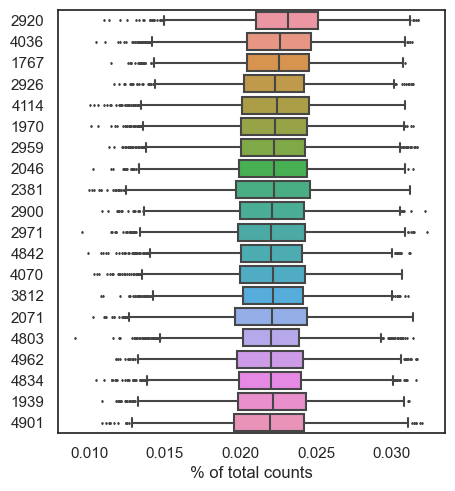

In [146]:
sc.pl.highest_expr_genes(adata, n_top=20, )

In [147]:
target_df

,1,2,3,4,5,6,7,8,9,10,...,9974,9978,9983,9987,9989,9991,9994,9999,allele,peptide
VPVKQIGEQ,-33.589726,-32.804547,-29.382308,-38.836464,-32.057075,-25.078257,-35.879710,-36.025140,-32.923047,-28.597129,...,-42.692282,-43.592213,-42.868180,-43.208135,-35.150638,-44.852251,-35.017644,-48.261902,Dummy_allele_7,VPVKQIGEQ
LDWWCESHV,-43.555957,-33.345235,-39.838340,-48.280282,-25.212543,-38.648253,-33.489293,-29.835659,-39.233523,-29.627618,...,-36.442903,-41.927532,-43.599777,-45.303143,-37.340800,-36.478145,-43.459457,-40.096782,Dummy_allele_6,LDWWCESHV
LTPTNHKCL,-38.949646,-38.410877,-34.542356,-35.509570,-33.400199,-48.096759,-38.432839,-42.820539,-29.456792,-34.003587,...,-37.057169,-39.493548,-31.276504,-45.091998,-29.387873,-37.092411,-24.919498,-31.425436,Dummy_allele_8,LTPTNHKCL
WIVKQTGCQ,-37.210997,-27.845001,-33.003579,-42.457735,-27.097530,-36.701280,-31.266012,-31.411442,-32.385407,-23.637583,...,-44.833414,-39.125143,-39.087462,-38.881389,-40.604487,-46.993382,-38.135731,-40.433350,Dummy_allele_7,WIVKQTGCQ
LWEIDQIVV,-48.157088,-37.946366,-43.288117,-44.704484,-28.128454,-39.719356,-38.379772,-34.179650,-42.669914,-33.077395,...,-48.518472,-37.460139,-21.761511,-40.634603,-45.647221,-48.553715,-44.146679,-30.761896,Dummy_allele_8,LWEIDQIVV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FPVRYCSDQ,-22.532338,-21.940679,-27.689502,-27.256662,-30.557790,-21.792028,-24.822322,-24.967752,-31.230241,-27.097843,...,-31.019780,-33.869525,-34.604476,-43.264124,-35.564589,-34.613731,-25.181762,-38.478646,Dummy_allele_7,FPVRYCSDQ
VPSRRGGWQ,-27.024302,-26.239123,-32.181467,-32.271040,-34.823696,-18.355242,-29.281748,-29.427178,-35.722205,-31.396287,...,-35.018070,-40.719921,-39.899318,-34.615641,-33.294594,-39.091442,-38.702809,-41.017931,Dummy_allele_7,VPSRRGGWQ
FNEKIYSFL,-34.102303,-43.167476,-29.894885,-38.826628,-34.011116,-34.345807,-33.491191,-29.291069,-29.276713,-38.960057,...,-46.430071,-36.965994,-30.269271,-45.295920,-40.730228,-43.068313,-35.363371,-34.491791,Dummy_allele_6,FNEKIYSFL
FNVSRKGRL,-20.415107,-29.480279,-25.041597,-25.661845,-37.566716,-29.466741,-23.867330,-24.012760,-24.423425,-34.106769,...,-39.211311,-36.542211,-33.845490,-36.211430,-39.574555,-43.284683,-31.101494,-39.239458,Dummy_allele_8,FNVSRKGRL


## 1. Normalize

In [148]:
# sc.pp.scale(adata)

In [149]:
adata.X

array([[33.5897264 , 32.8045469 , 29.38230816, ..., 44.8522506 ,
        35.01764363, 48.26190164],
       [43.55595728, 33.34523526, 39.83833988, ..., 36.47814504,
        43.45945682, 40.09678226],
       [38.94964557, 38.41087681, 34.54235553, ..., 37.09241138,
        24.91949761, 31.42543575],
       ...,
       [34.10230346, 43.16747553, 29.89488522, ..., 43.06831325,
        35.36337123, 34.49179099],
       [20.41510737, 29.48027944, 25.04159714, ..., 43.28468275,
        31.1014936 , 39.23945755],
       [35.03618733, 44.10135941, 30.62889729, ..., 35.66814875,
        32.66948822, 31.36065025]])

In [150]:
sc.pp.normalize_total(adata) # Total-count normalize (library-size correct) the data matrix X to 10,000 reads per cell, so that counts become comparable among cells.
sc.pp.log1p(adata) # log-normalization

In [151]:
adata.X

array([[3.52570531, 3.50275637, 3.39608332, ..., 3.80744116, 3.56613626,
        3.87913987],
       [3.77416573, 3.51403903, 3.68708893, ..., 3.60127684, 3.77199869,
        3.69339382],
       [3.69451112, 3.68093075, 3.57759455, ..., 3.64689781, 3.26179136,
        3.48579357],
       ...,
       [3.57926326, 3.80911022, 3.45150418, ..., 3.80686147, 3.61457962,
        3.59030463],
       [3.10117053, 3.45468387, 3.29708572, ..., 3.82863299, 3.50656975,
        3.73275559],
       [3.59740243, 3.82186459, 3.46689908, ..., 3.61479359, 3.52944515,
        3.4897805 ]])

## 2. Highly variable features

In [152]:
import matplotlib.pyplot as plt
# sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
# sc.pl.highly_variable_genes(adata, show=False) # can not scale only x

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\seaborn\categorical.py:470: FutureWarning: iteritems is deprecated and will be removed in a future version. Use .items instead.
  plot_data = [np.asarray(s, float) for k, s in iter_data]


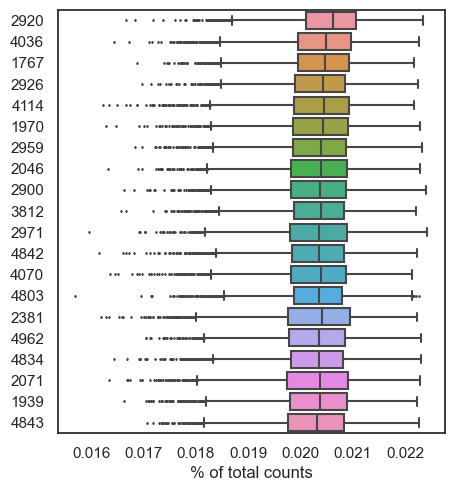

In [153]:
sc.pl.highest_expr_genes(adata, n_top=20, )



## 3. PCA

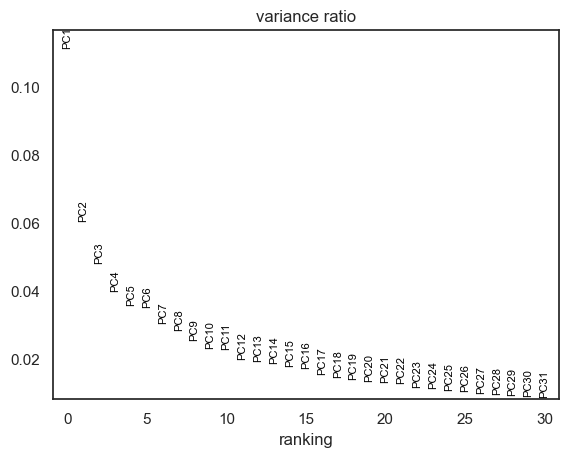

In [154]:
sc.tl.pca(adata, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata)

## Regress out PC1

In [37]:
#not doing now
# adata.obsm['X_pca'][:, 0:1]  = 0
# adata.varm['PCs'][:, 0:1] = 0
# adata.uns['pca']['variance_ratio'][0:1] = 0
# adata.uns['pca']['variance'][0:1] = 0
# adata.obsm['X_pca']

In [37]:
# sc.pl.pca_variance_ratio(adata)

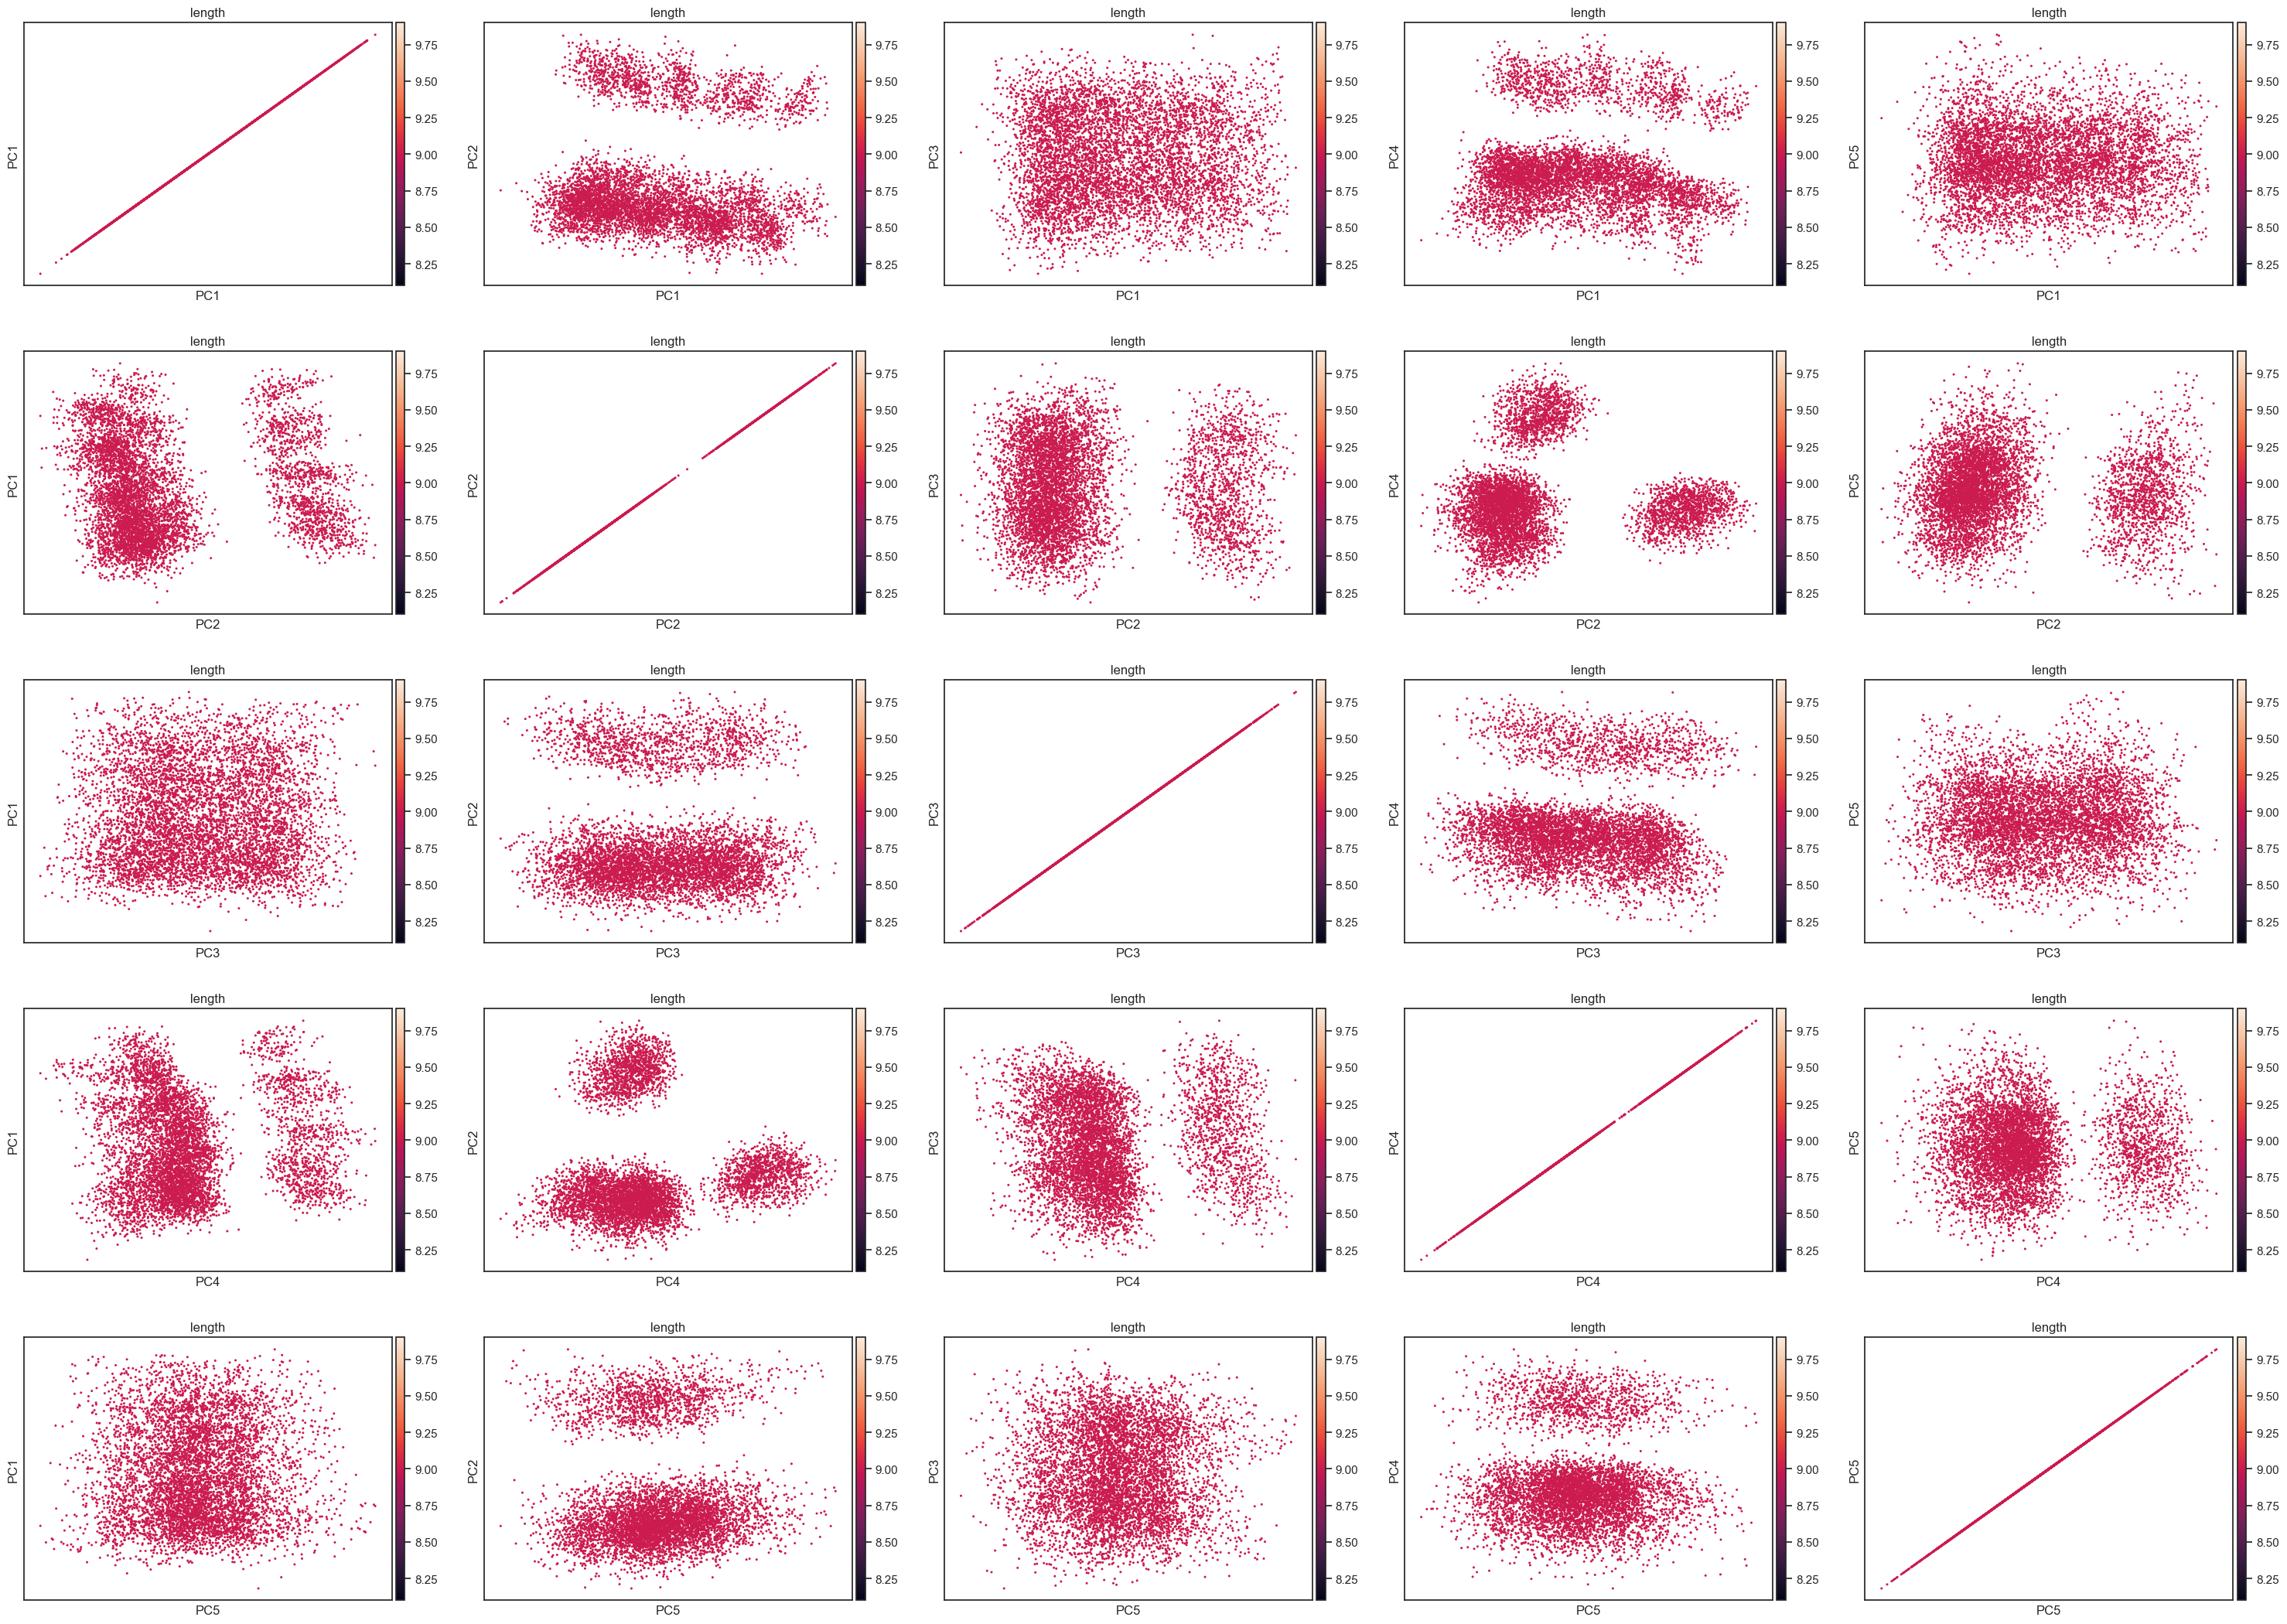

In [193]:
#Some plots for PCA distributions
from itertools import product
sc.pl.pca(adata, color='length',dimensions=list(product(range(5), repeat=2)), ncols=5 )
# sc.pl.pca(adata, color='length',dimensions=[(i,i) for i in range(20)], ncols=5 )

In [194]:
# import seaborn as sns
# n=10
# fig, axes = plt.subplots(nrows=n//5, ncols=5, figsize=(25, 5*n/5))

# for i,ax in enumerate(axes.flatten()):
#     df = pd.DataFrame({f"PC_{i}":adata.obsm['X_pca'][:,i], "length" : adata.obs['length'].values })
#     sns.histplot(df, x=f"PC_{i}", hue='length', ax=ax )

## 4. Neighborhood graph and umap

In [155]:
from itertools import product
import seaborn as sns
import matplotlib.pyplot as plt

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  cax = scatter(


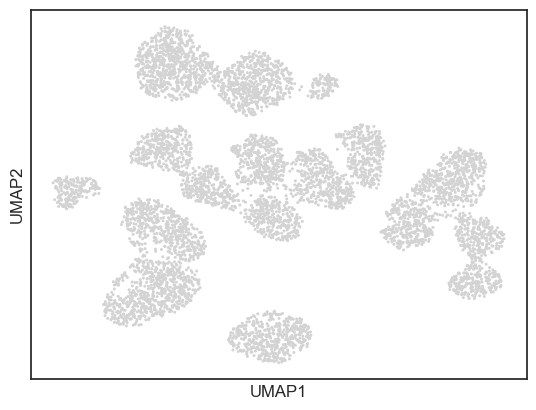

In [199]:
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=4, metric="euclidean")
sc.tl.umap(adata, min_dist=1, n_components=2)
sc.pl.umap(adata)

## 5.  Cell clusters

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


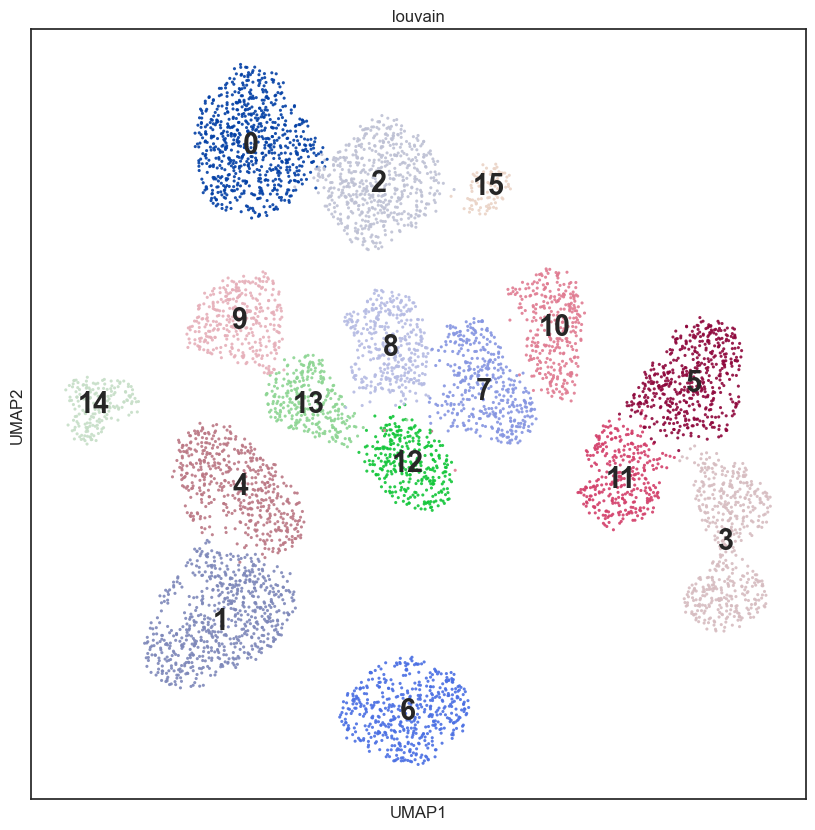

In [200]:
from matplotlib.pyplot import rc_context
with rc_context({'figure.figsize': (10, 10)}):
    sc.tl.louvain(adata, resolution=0.5)
    sc.tl.leiden(adata, resolution=0.7)
    sc.pl.umap(adata, color='louvain', s=20, 
           # add_outline=True, 
           legend_loc='on data',
          legend_fontsize='xx-large',
          legend_fontweight='bold', 
           alpha=0.9)

    # sc.pl.umap(adata, color='louvain', s=20)


<AxesSubplot: xlabel='0', ylabel='1'>

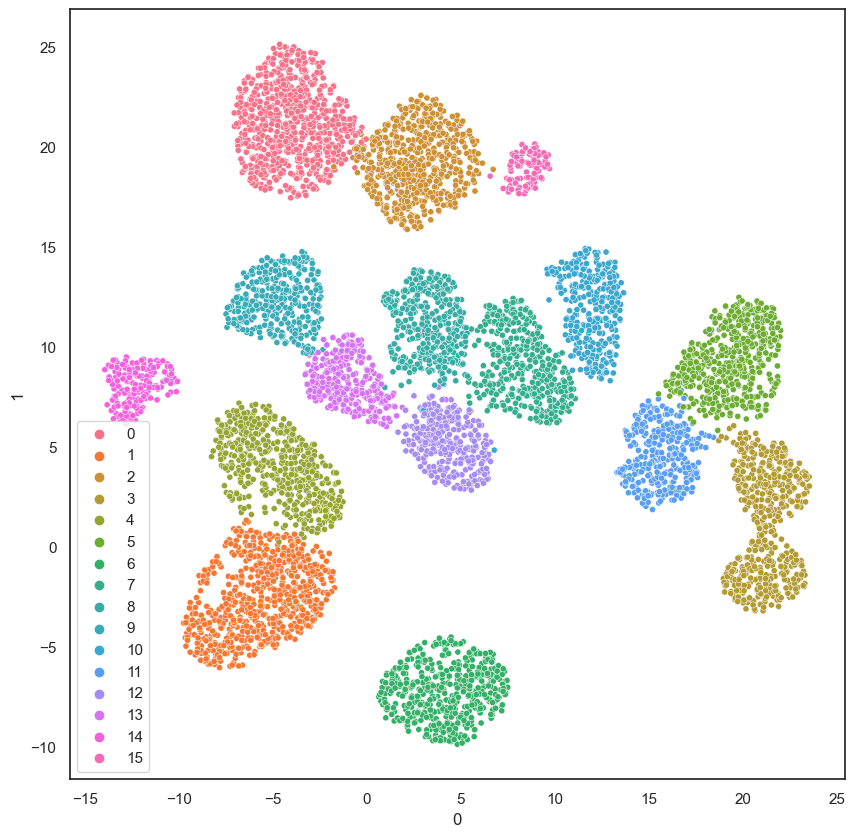

In [201]:
sns.set_theme(style="white")
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=20, hue=adata.obs['louvain'].values)



## 6. Color by allele

In [202]:
adata_copy = adata_copy = adata[~adata.obs['allele'].str.contains('imm')]

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\anndata\compat\_overloaded_dict.py:106: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  self.data[key] = value
C:\Tools\Anaconda\envs\pomegranate\lib\contextlib.py:126: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  next(self.gen)
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


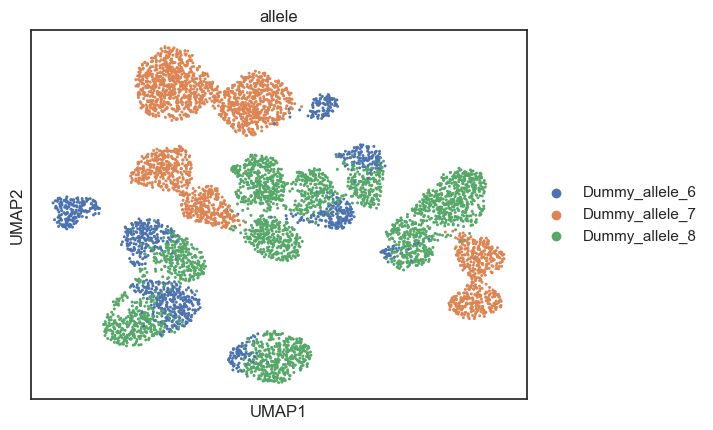

In [203]:
sc.pl.umap(adata_copy, color="allele")

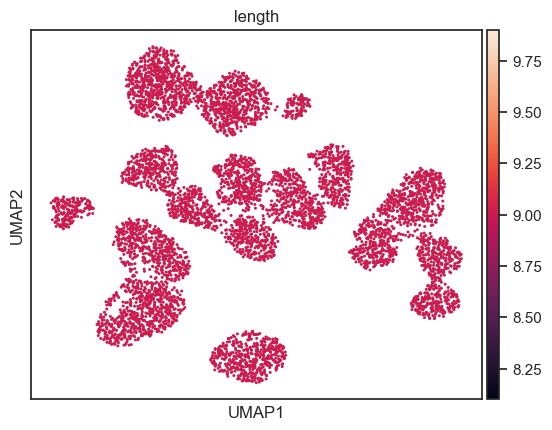

In [204]:
sc.pl.umap(adata_copy, color="length")

<AxesSubplot: xlabel='0', ylabel='1'>

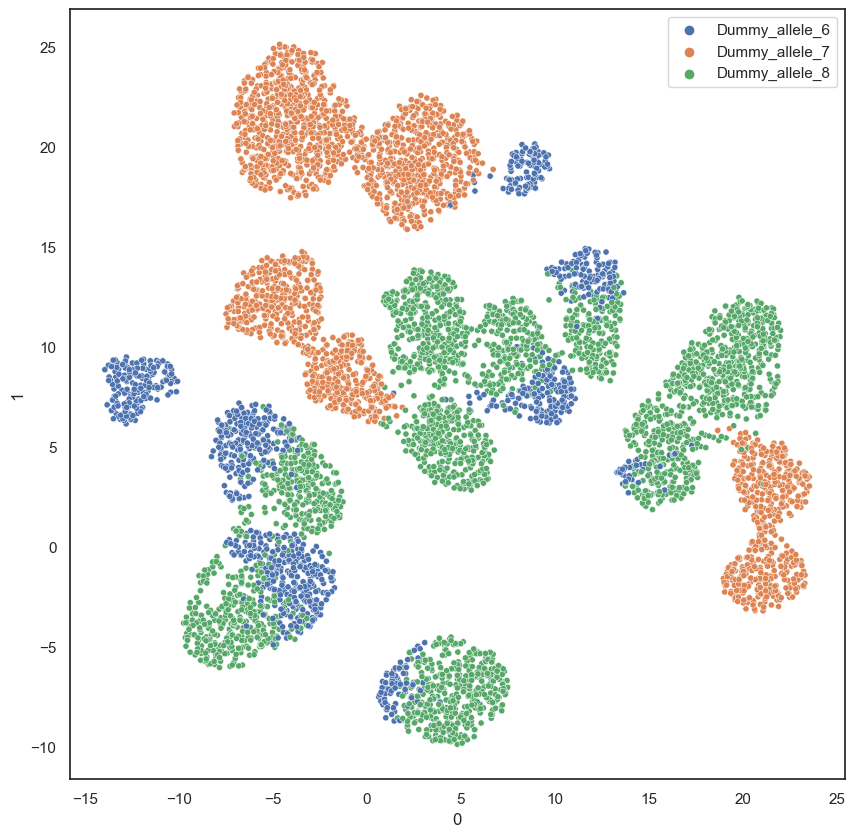

In [208]:
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata_copy.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=20, hue=adata_copy.obs['allele'].values)

<AxesSubplot: xlabel='0', ylabel='1'>

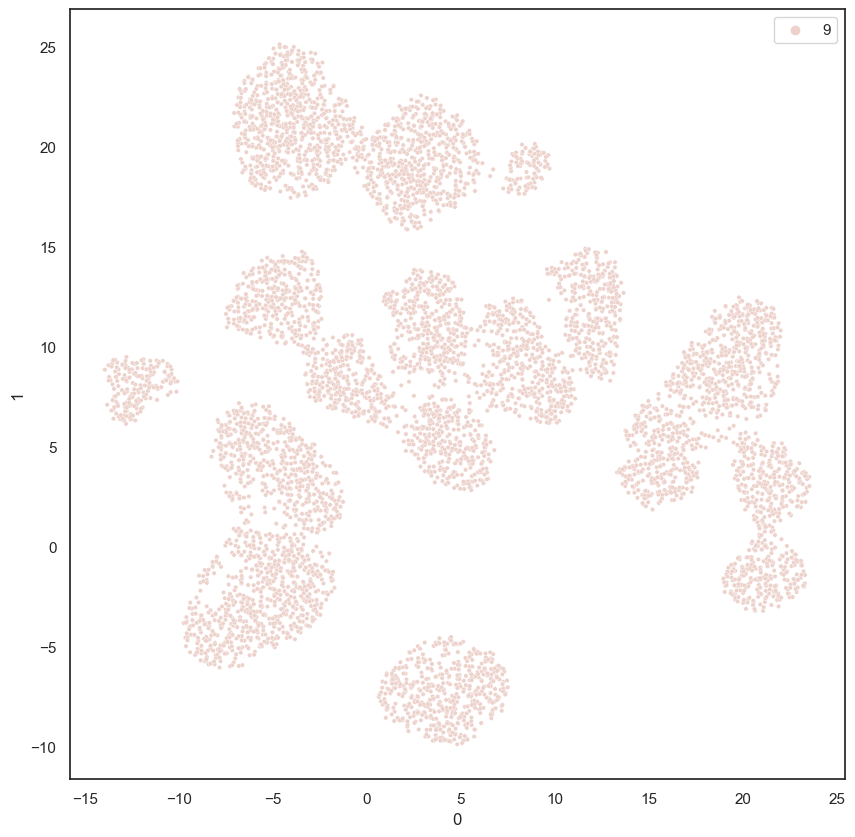

In [209]:
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata_copy.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=10, hue=adata_copy.obs['length'].values)

## Color by immunogenicity

In [210]:
adata.obs['immunogenic'] = adata.obs['allele'].str.contains('imm').astype(int)
# adata.obs['target_sub'] = adata.obs['peptide'].map(lambda x: x in gibbs_set).astype(int)
adata.obs

,peptide,allele,length,louvain,leiden,immunogenic
0,VPVKQIGEQ,Dummy_allele_7,9,0,0,0
1,LDWWCESHV,Dummy_allele_6,9,1,1,0
2,LTPTNHKCL,Dummy_allele_8,9,7,6,0
3,WIVKQTGCQ,Dummy_allele_7,9,9,8,0
4,LWEIDQIVV,Dummy_allele_8,9,1,1,0
...,...,...,...,...,...,...
6568,FPVRYCSDQ,Dummy_allele_7,9,3,13,0
6569,VPSRRGGWQ,Dummy_allele_7,9,0,0,0
6570,FNEKIYSFL,Dummy_allele_6,9,11,10,0
6571,FNVSRKGRL,Dummy_allele_8,9,3,13,0


In [211]:
adata.obs['immunogenic']

0       0
1       0
2       0
3       0
4       0
       ..
6568    0
6569    0
6570    0
6571    0
6572    0
Name: immunogenic, Length: 6573, dtype: int32

<AxesSubplot: xlabel='0', ylabel='1'>

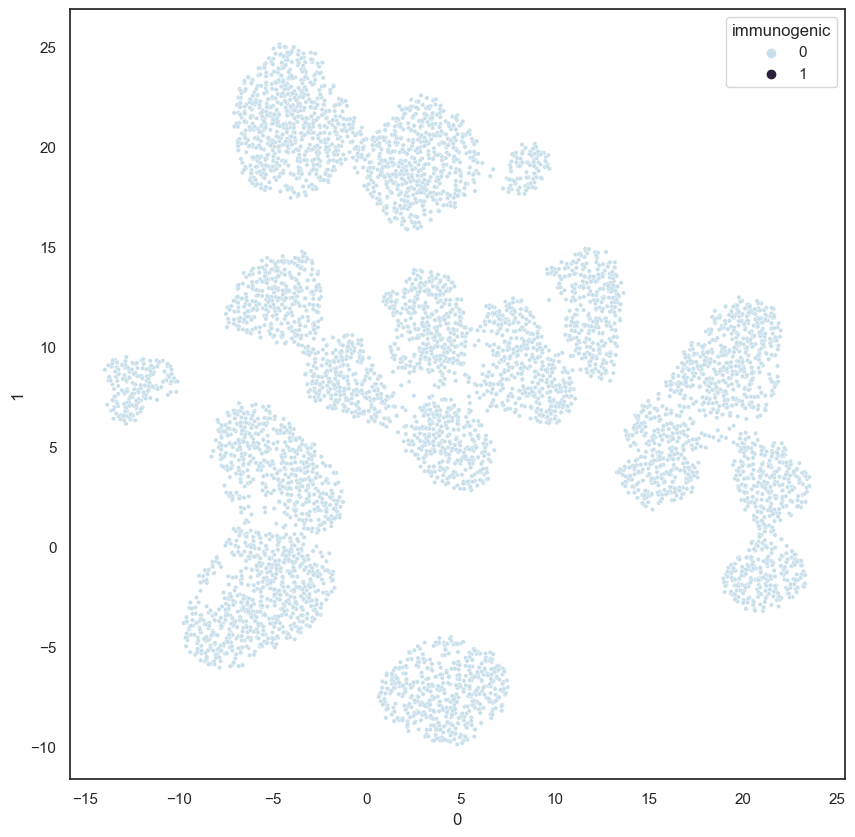

In [212]:
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata.obsm['X_umap']).copy()
df['immunogenic'] = adata.obs['immunogenic'].values
colors = sns.color_palette("ch:s=.25,rot=-.25", 2)
hue_order = [0, 1]
sns.scatterplot(data=df.sort_values(by='immunogenic'), x=0, y=1,s=10, hue='immunogenic', palette=colors, hue_order=hue_order)

## 7. Plot cluster motifs

In [213]:
peptides_df = adata.obs.copy()

In [214]:
counts = dict(peptides_df['allele'].value_counts())
counts = dict(sorted(counts.items()))
# prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
b_counts = [(key,value) if not key.endswith('imm') else 0 for key,value in counts.items() ]
i_counts = [value if key.endswith('imm') else 0 for key,value in counts.items() ]
counts_str = "\n".join([f'{key}: B {b_value}, I {i_value}' for (key,b_value), i_value in zip(b_counts, i_counts)])


In [215]:
import logomaker
def make_logo(df, length=9, cluster_num=0, ax=None, description_ax=None):
    filtered = df[df['length'] == length]
    if len(filtered) > 0:
        matrix = logomaker.alignment_to_matrix(filtered['peptide'].values)
        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        counts = dict(filtered['allele'].value_counts())
        counts = dict(sorted(counts.items()))
        # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
        ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=ax)
        b_counts = [(key,value) if not key.endswith('imm') else 0 for key,value in counts.items() ]
        i_counts = [value if key.endswith('imm') else 0 for key,value in counts.items() ]

        counts_str = "\n".join([f'{key}: B {b_value}, I {i_value}' for (key,b_value), i_value in zip(b_counts, i_counts)])
        # if description_ax is not None:
        #     description_ax.text(0.1, 0.1,f'Allele counts:\n {counts_str}', fontsize=9) #add text
        ww_logo.ax.set_title(f"Cluster {cluster_num} \n {counts_str}")

In [216]:
sns.set_theme(style="white")

In [217]:
def plot_all_cluster_motifs(source_df, cluster_column = 'leiden', target_length=9 ):
    unique_clusters = peptides_df[cluster_column].unique()
    fig, axes = plt.subplots(nrows=len(unique_clusters), ncols=2, figsize=(9,2*len(unique_clusters)))
    for i, cluster_num in enumerate(unique_clusters):
        print(i)
        ax = axes[i, 0]
        df = source_df[source_df[cluster_column] == cluster_num]
        make_logo(df,length=target_length, cluster_num=cluster_num, ax=ax)
        # Additionaly plot immunogenic peptides
        ax = axes[i, 1]
        df = source_df[(source_df[cluster_column] == cluster_num) & (source_df['immunogenic'] == 1)]
        print(len(df))
        if len(df) > 0:
            make_logo(df,length=target_length, cluster_num=cluster_num, ax=ax)
            # Put the legend out of the figure
    plt.tight_layout()
    fig.savefig('temp.png', transparent=False)



0
0
1
0
2
0
3
0
4
0
5
0
6
0
7
0
8
0
9
0
10
0
11
0
12
0
13
0
14
0
15
0


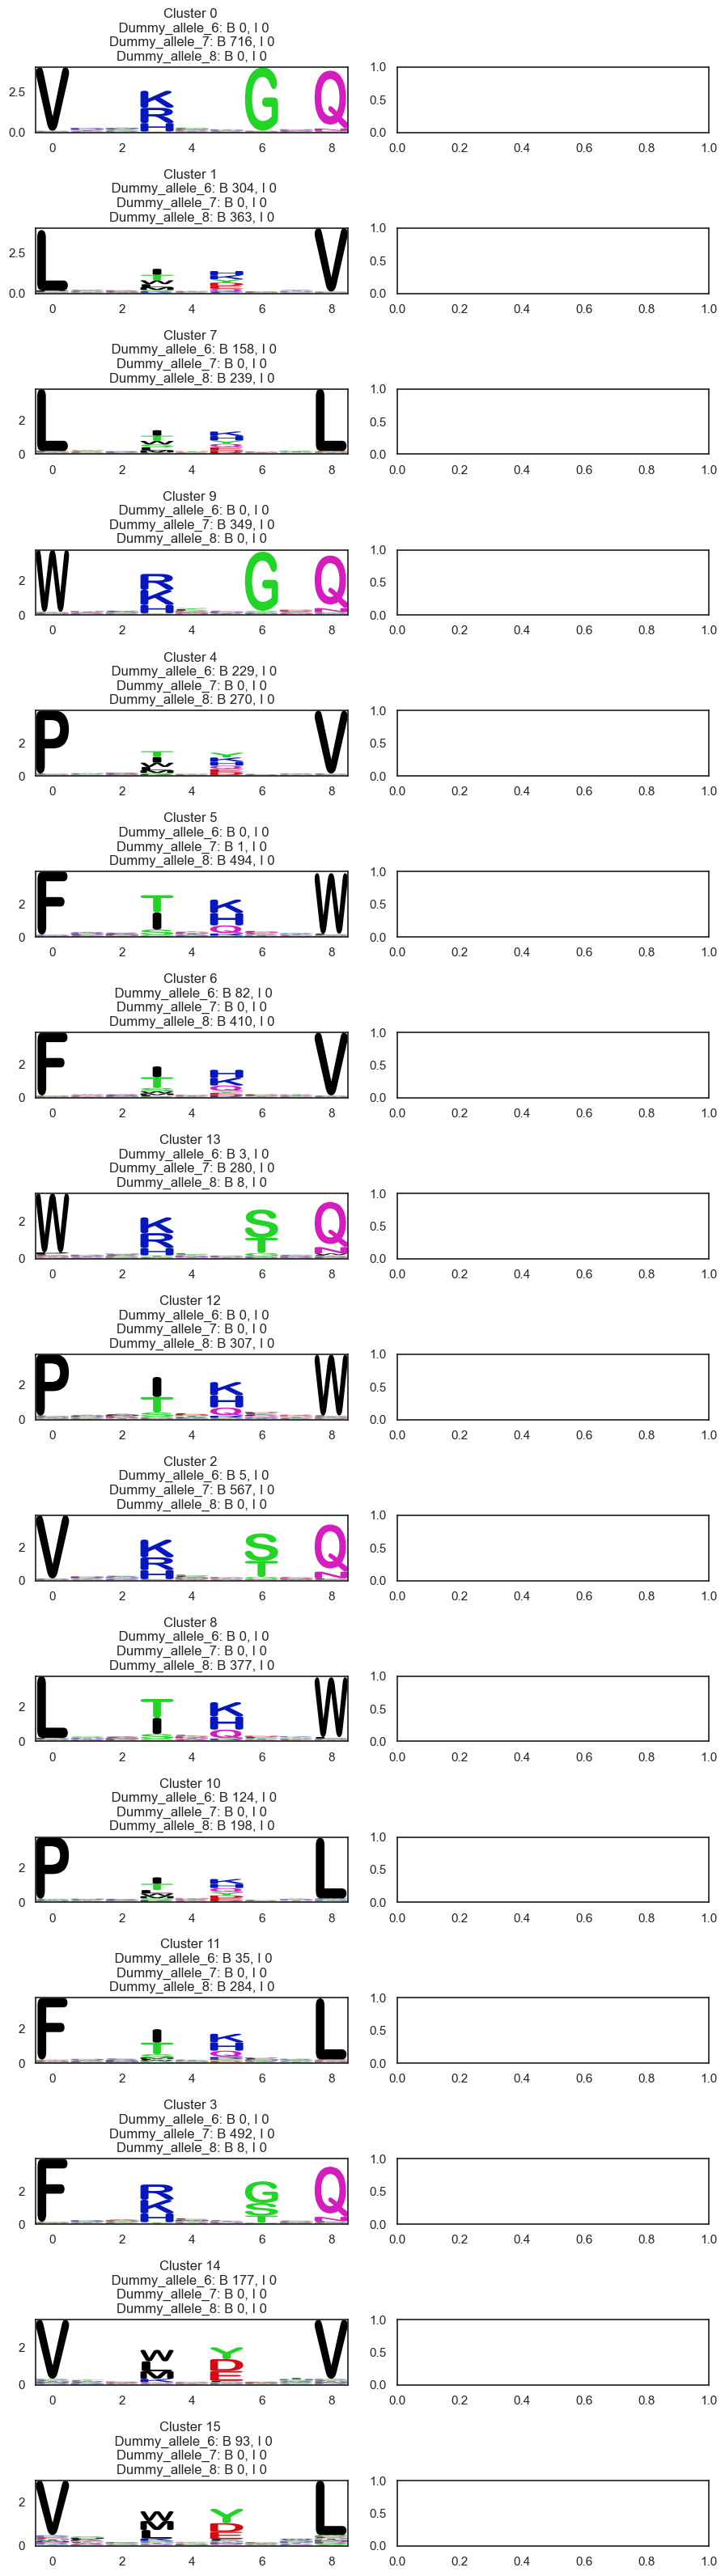

In [218]:
plot_all_cluster_motifs(peptides_df, 'louvain',9)

0
0
1
0
2
0
3
0
4
0
5
0
6
0
7
0
8
0
9
0
10
0
11
0
12
0
13
0
14
0
15
0
16
0
17
0
18
0
19
0
20
0
21
0
22
0
23
0


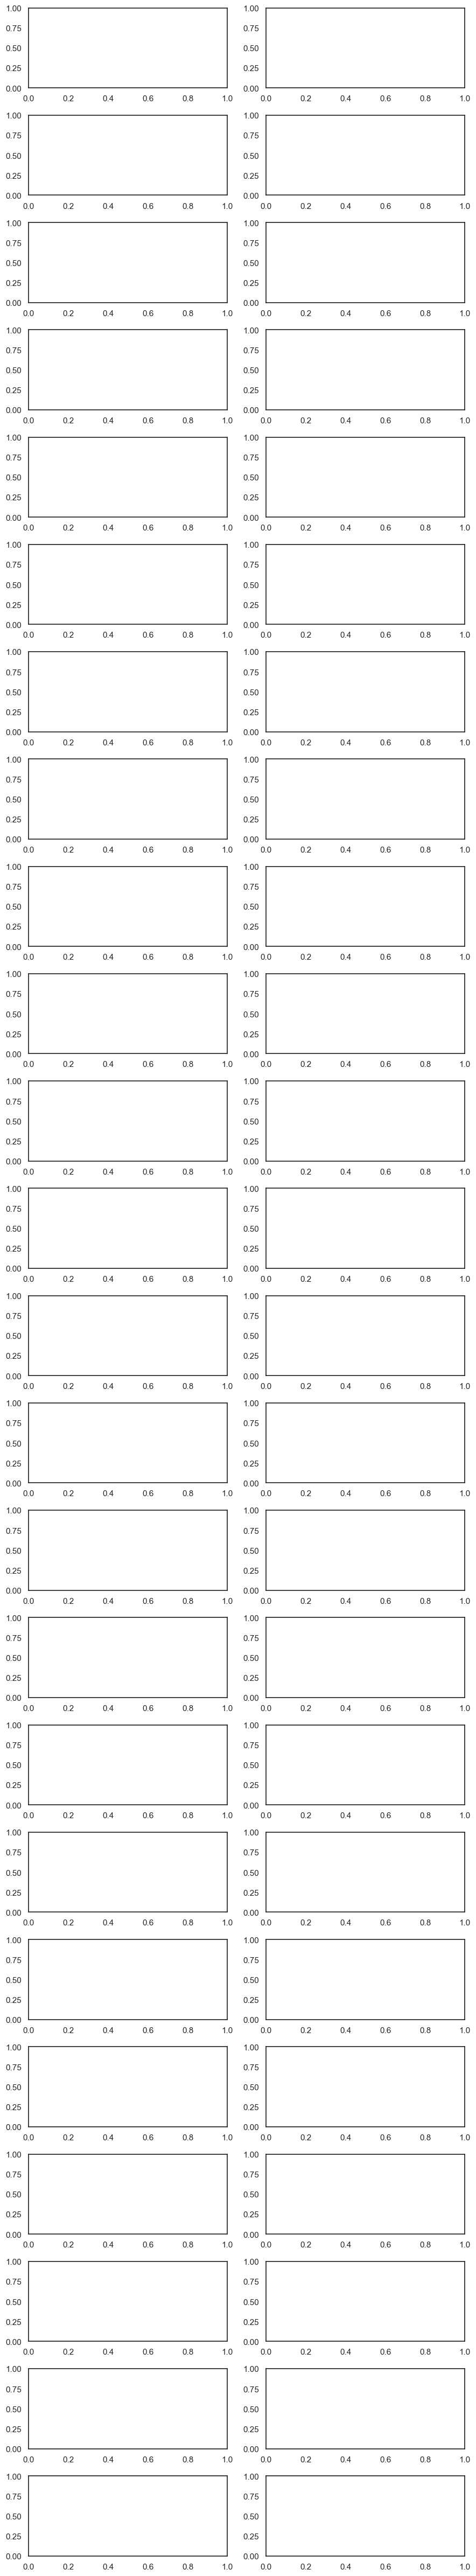

In [66]:
plot_all_cluster_motifs(peptides_df, 'leiden', 10)

0
0
1
0
2
0
3
0
4
0


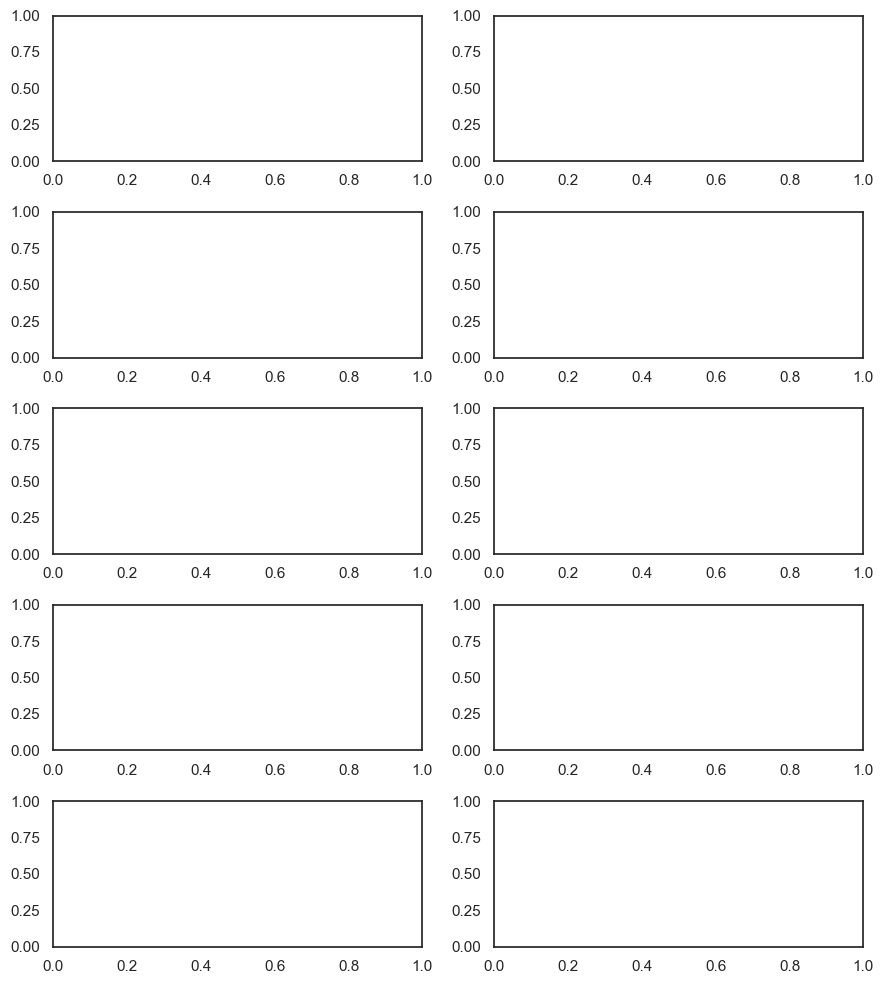

In [57]:
plot_all_cluster_motifs(peptides_df, 'leiden', 11)

0
0
1
0
2
0
3
0
4
0


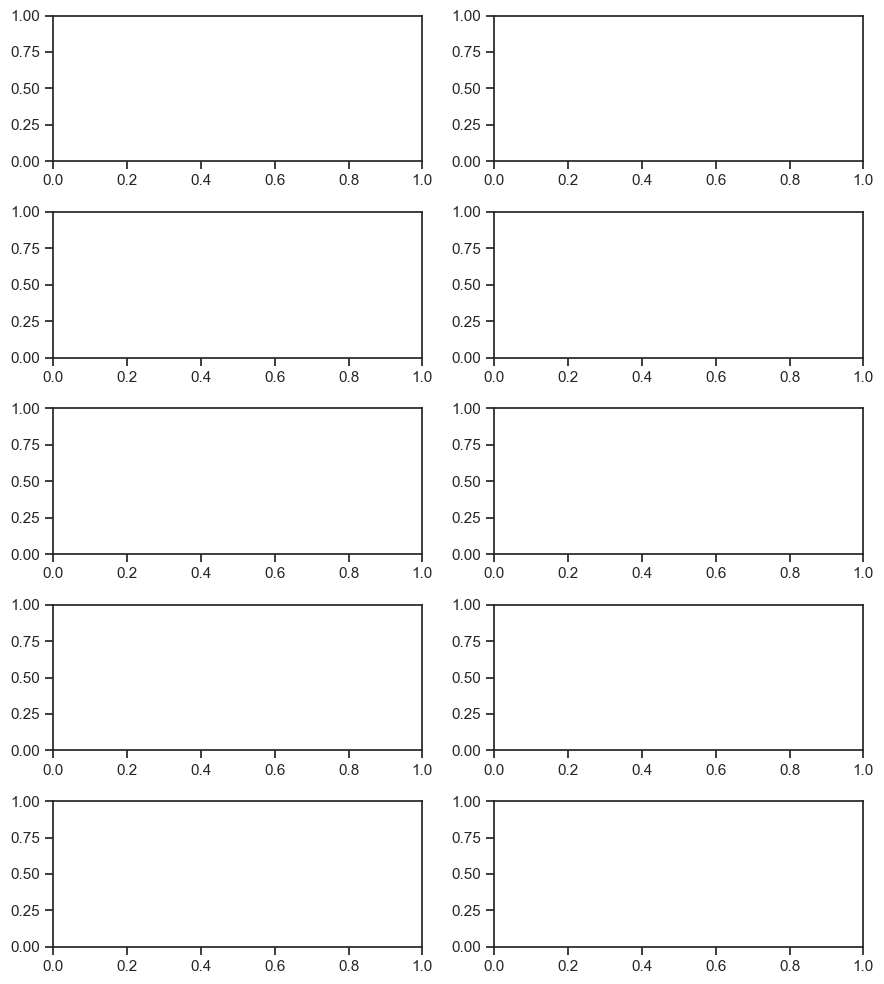

In [58]:
sns.set_style("ticks")
plot_all_cluster_motifs(peptides_df, 'leiden', 15)

In [85]:
filtered_peptides = peptides_df[peptides_df['louvain'].isin(['1'])]['peptide'].values

In [86]:
filtered_peptides

array(['LSAMMLDRL', 'FDFQKAYDL', 'YDERLNESL', 'YLLESVNKL', 'WVQMCSRTL',
       'FAKQPAYTL', 'FHYSKTQKL', 'YQAQSAVPL', 'YKLEAQETL', 'FLYQQQGRL',
       'YVATVSEAL', 'VPHISRQRL', 'YFAERVTSL', 'YVKQNTLKL', 'EACPLPHKL',
       'YSDQATLLL', 'AEKVVYKLL', 'YESVAAKNL', 'LQNPGVADL', 'TSVIPAARL',
       'YHKVTAAEL', 'MERQGKTPL', 'KTSFSSRLL', 'FEKIPAETL', 'WIGAIAEPL',
       'IELMPNITL', 'LWDYFSLVL', 'LTKFVAAAL', 'FRSMEAIFL', 'WKLGEPLEL',
       'LERESVPSL', 'CVAVYDSPL', 'IKLMFNITL', 'KVESCCNWL', 'FFIKLPIIL',
       'FTQQQPQEL', 'FDNMMAQNL', 'WLVRNNSYL', 'WTLNSAGYL', 'FWAQLSTAL',
       'FCAMPYNIL', 'FQMAYSNLL', 'FRQMVEAQL', 'FFNKTLILL', 'MFESKSMKL',
       'VQKVVVHPL', 'VKWMAPESL', 'FGEARSLYL', 'FIEEHATKL', 'FTTVIKTLL',
       'WTIVRVEIL', 'FEKFMEPKL', 'LGSEISVIL', 'LFEMEARKL', 'QSSEPHCAL',
       'FRKNFATSL', 'YEDVNPVLL', 'WFSIQNNQL', 'NVVPPALHL', 'ISIPEYKEL',
       'ARLFKAFIL', 'FVIFGATSL', 'FAQEKTKFL', 'YFARRFKYL', 'ILAQGAEPL',
       'LSSFGDLRL', 'IFFTTSLFL', 'FQLESVNKL', 'MKTSFSSRL', 'LQVV

In [ ]:
matrix_df = target_df.drop(columns=['allele', 'peptide'])

In [ ]:
g = sns.clustermap(matrix_df,
                   figsize=(7, 5),
                   row_cluster=False,
                   dendrogram_ratio=(.1, .2),
                   cbar_pos=(0, .2, .03, .4))

In [ ]:
g = sns.clustermap(matrix_df, metric="correlation")

In [ ]:
g = sns.clustermap(matrix_df, z_score=0, cmap="vlag")

In [ ]:
indicies = g.dendrogram_col.reordered_ind

In [ ]:
colums_to_check = list(indicies[0:5])

In [ ]:
target_df.columns

In [ ]:
colums_to_check = list(target_df.columns[indicies[-5:]]) + ['peptide']

In [ ]:
colums_to_check = ['4394','3775', '2388', '3810', 'peptide' ]

In [ ]:
selected_col = '3810'
sorted_subset = target_df[colums_to_check].sort_values(by=selected_col, ascending=False)[:100]

In [ ]:
matrix = logomaker.alignment_to_matrix(sorted_subset['peptide'].values)
info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')      
ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')
ww_logo.ax.set_title(f"path {selected_col}")

In [ ]:
sorted_subset

In [ ]:
selected_peptides = peptides_df[~((peptides_df['leiden'] == '0') | (peptides_df['leiden'] == '8') )]

In [ ]:
selected_peptides

## Hierarchical custering

In [ ]:
df = target_df.copy()
X = df.drop(columns=['allele', 'peptide']).values
TOP = 5000
X = X.T[:TOP]
print(f"Shape of data {X.shape}")

In [ ]:
target_df

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import pairwise_distances
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 3))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'), ax=ax)
ax.set_xlabel('Paths')
ax.set_ylabel('Distance_threshold')
ax.set_title(f"Clustering dendrogram")
ax.set_xticks([])

In [ ]:
model = AgglomerativeClustering(
    n_clusters=None, linkage="ward", affinity='euclidean', distance_threshold=1500
)
model.fit(X)

In [244]:
target_df

,0,1,2,3,4,5,6,7,8,9,...,4992,4993,4994,4995,4996,4997,4998,4999,allele,peptide
DKDLQRLRSLNQTVH,-58.419884,-64.473083,-65.175252,-63.646565,-54.684358,-63.938666,-63.951582,-63.965147,-67.924724,-62.446082,...,-85.198456,-74.902834,-85.053688,-85.843603,-84.639948,-76.802411,-85.776442,-78.109559,HLA-DRB1*01:01,DKDLQRLRSLNQTVH
LRAHRLHQLAFDTYQ,-64.651944,-64.636983,-60.401893,-60.131140,-66.920076,-64.481268,-61.412098,-60.848552,-64.007000,-59.740403,...,-81.666961,-81.170169,-78.150214,-73.960243,-81.033912,-78.540228,-77.755776,-82.077609,HLA-DRB1*01:01,LRAHRLHQLAFDTYQ
LLRIPTHRHIIGEGC,-72.168699,-70.929351,-68.535677,-72.371721,-73.607376,-73.764365,-73.223832,-70.706964,-72.998406,-68.208229,...,-69.797705,-84.504507,-82.825039,-88.041395,-83.495762,-82.710716,-80.934399,-91.335021,HLA-DRB1*01:01,LLRIPTHRHIIGEGC
NGVGVDIVSRISERV,-68.132530,-66.325481,-64.410513,-67.871478,-61.889843,-71.437180,-69.082840,-66.974359,-57.675615,-66.578970,...,-75.719702,-78.672597,-73.519184,-81.512082,-78.533680,-78.308378,-74.886800,-78.786400,HLA-DRB1*01:01,NGVGVDIVSRISERV
KHYCAPAGFAILKCN,-70.766889,-80.132654,-85.166402,-78.400659,-63.862776,-75.817134,-82.606437,-84.157699,-82.096147,-83.751422,...,-83.096786,-81.108058,-86.999428,-85.320754,-91.280205,-79.376665,-82.647755,-86.871656,HLA-DRB1*01:01,KHYCAPAGFAILKCN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
EGKPTEKHIQIRSTN,-63.111923,-71.412903,-67.128401,-72.524985,-67.550442,-68.386584,-63.724397,-70.624237,-68.655678,-72.017897,...,-77.499822,-88.560479,-76.296687,-80.287786,-77.762929,-82.892906,-81.611476,-88.892028,HLA-DRB1*01:01,EGKPTEKHIQIRSTN
VSEFTNVPDFELLLS,-68.808528,-68.605121,-67.397612,-68.439150,-53.947978,-69.826224,-70.707834,-69.298182,-69.418822,-68.733381,...,-77.399514,-78.425811,-68.803310,-71.656581,-76.001082,-69.358856,-70.095857,-80.354747,HLA-DRB1*01:01,VSEFTNVPDFELLLS
REKLQAANAEDIKSG,-62.471299,-65.859362,-69.423783,-68.526381,-49.620148,-69.006449,-71.912178,-71.320785,-66.787168,-68.603530,...,-80.976197,-76.079915,-73.627477,-65.851151,-75.425375,-78.282643,-73.637672,-73.069197,HLA-DRB1*01:01,REKLQAANAEDIKSG
EDPAFYMLKGKLQYE,-62.907405,-53.450162,-55.169928,-55.341064,-67.773472,-51.332096,-53.024576,-56.286502,-53.181091,-56.939694,...,-83.344627,-87.570761,-80.544334,-85.741874,-85.263102,-79.661321,-84.006801,-81.735793,HLA-DRB1*01:01,EDPAFYMLKGKLQYE


In [245]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import pairwise_distances
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt

[]

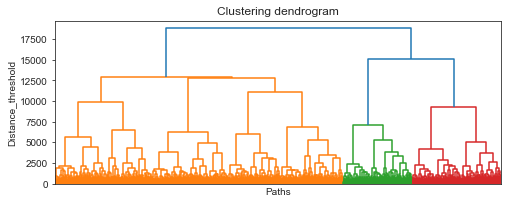

In [246]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 3))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'), ax=ax)
ax.set_xlabel('Paths')
ax.set_ylabel('Distance_threshold')
ax.set_title(f"Clustering dendrogram")
ax.set_xticks([])

In [87]:
model = AgglomerativeClustering(
    n_clusters=None, linkage="ward", affinity='euclidean', distance_threshold=1500
)
model.fit(X)

AgglomerativeClustering(distance_threshold=1500, n_clusters=None)

In [88]:
unique_labels_counts = pd.Series(model.labels_).value_counts().sort_values(ascending=False)
path_to_label = {df.columns[i]:model.labels_[i] for i in range(X.shape[0])}
unique_labels_counts

0     42
2     36
10    33
3     32
4     28
9     25
5     25
6     22
8     20
1     20
7     14
11    12
dtype: int64

In [89]:
peptide_df = pd.DataFrame({"peptide": df.index.values, "allele": df['allele']})

In [90]:
peptide_df

,peptide,allele
AFLIGANYLGKPKEQ,AFLIGANYLGKPKEQ,HLA-DRB1*01:01
NQSLGLENIECLKKN,NQSLGLENIECLKKN,HLA-DRB1*01:01
HIDLMSKLAVECKSS,HIDLMSKLAVECKSS,HLA-DRB1*01:01
AASGADGTYDITKLG,AASGADGTYDITKLG,HLA-DRB1*01:01
INLWKSGLFQLIFFL,INLWKSGLFQLIFFL,HLA-DRB1*01:01
...,...,...
DHFTNLYPQLIKNPS,DHFTNLYPQLIKNPS,HLA-DRB1*01:01
DKNEAILQFGDILGL,DKNEAILQFGDILGL,HLA-DRB1*01:01
KAFAEGLSGEPKGGA,KAFAEGLSGEPKGGA,HLA-DRB1*01:01
NTNTDVKDWLDGSRG,NTNTDVKDWLDGSRG,HLA-DRB1*01:01


In [91]:
for label in unique_labels_counts.index:
    # peptide_df[f'path_gr_{label}'] = np.exp(df[ [path for path, cur_label in path_to_label.items() if cur_label == label]]).mean(axis=1).values
    peptide_df[f'path_gr_{label}'] = df[[path for path, cur_label in path_to_label.items() if cur_label == label]].max(axis=1).values


In [92]:
peptide_df['max_label'] = peptide_df[[f'path_gr_{label}' for label in path_to_label.values()]].idxmax(axis=1)
peptide_df['len'] = peptide_df['peptide'].str.len()
peptide_df

,peptide,allele,path_gr_0,path_gr_2,path_gr_10,path_gr_3,path_gr_4,path_gr_9,path_gr_5,path_gr_6,path_gr_8,path_gr_1,path_gr_7,path_gr_11,max_label,len
AFLIGANYLGKPKEQ,AFLIGANYLGKPKEQ,HLA-DRB1*01:01,-65.150053,-58.322841,-54.666791,-67.620625,-61.179665,-59.131393,-61.857729,-61.698965,-64.989425,-65.760553,-55.466420,-61.874270,path_gr_10,15
NQSLGLENIECLKKN,NQSLGLENIECLKKN,HLA-DRB1*01:01,-67.036109,-64.027790,-69.316333,-60.970722,-57.711659,-62.655395,-68.419264,-69.906545,-59.806056,-66.789355,-65.146885,-71.119905,path_gr_4,15
HIDLMSKLAVECKSS,HIDLMSKLAVECKSS,HLA-DRB1*01:01,-57.676713,-62.923570,-62.246134,-68.526372,-64.920311,-69.741831,-74.416661,-67.032179,-60.926746,-65.996514,-59.198152,-63.682641,path_gr_0,15
AASGADGTYDITKLG,AASGADGTYDITKLG,HLA-DRB1*01:01,-65.652905,-67.515289,-65.172197,-62.913498,-67.332967,-60.400791,-66.800784,-67.988021,-67.391313,-63.202372,-66.120930,-63.826894,path_gr_9,15
INLWKSGLFQLIFFL,INLWKSGLFQLIFFL,HLA-DRB1*01:01,-68.338291,-64.210942,-70.500490,-69.055055,-60.336496,-64.306269,-63.149549,-71.121298,-59.072783,-70.507490,-74.116714,-60.935711,path_gr_8,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
DHFTNLYPQLIKNPS,DHFTNLYPQLIKNPS,HLA-DRB1*01:01,-71.566372,-63.498523,-64.239318,-63.166224,-69.116046,-50.984498,-63.503858,-72.864656,-70.144767,-62.202834,-68.513908,-63.395647,path_gr_9,15
DKNEAILQFGDILGL,DKNEAILQFGDILGL,HLA-DRB1*01:01,-57.320585,-68.315874,-67.084332,-52.848377,-61.015278,-64.809790,-61.543548,-68.566201,-60.013017,-55.615617,-66.854914,-65.392677,path_gr_3,15
KAFAEGLSGEPKGGA,KAFAEGLSGEPKGGA,HLA-DRB1*01:01,-60.222790,-63.701712,-66.983999,-60.038793,-56.358890,-56.550581,-52.986911,-53.503015,-58.031488,-57.500843,-63.031343,-58.814684,path_gr_5,15
NTNTDVKDWLDGSRG,NTNTDVKDWLDGSRG,HLA-DRB1*01:01,-70.651168,-70.248486,-71.483216,-61.060806,-70.513864,-67.259028,-71.332354,-66.713178,-70.889953,-64.313448,-70.502949,-63.610146,path_gr_3,15


In [93]:
peptide_df.max_label.value_counts()

path_gr_0     1516
path_gr_8     1486
path_gr_3      852
path_gr_9      726
path_gr_1      493
path_gr_10     438
path_gr_4      376
path_gr_2      371
path_gr_5      165
path_gr_11     139
path_gr_7       89
path_gr_6       24
Name: max_label, dtype: int64

In [94]:
peptide_df.groupby(['max_label','allele', 'len'])['peptide'].count()

max_label   allele          len
path_gr_0   HLA-DRB1*01:01  15     1516
path_gr_1   HLA-DRB1*01:01  15      493
path_gr_10  HLA-DRB1*01:01  15      438
path_gr_11  HLA-DRB1*01:01  15      139
path_gr_2   HLA-DRB1*01:01  15      371
path_gr_3   HLA-DRB1*01:01  15      852
path_gr_4   HLA-DRB1*01:01  15      376
path_gr_5   HLA-DRB1*01:01  15      165
path_gr_6   HLA-DRB1*01:01  15       24
path_gr_7   HLA-DRB1*01:01  15       89
path_gr_8   HLA-DRB1*01:01  15     1486
path_gr_9   HLA-DRB1*01:01  15      726
Name: peptide, dtype: int64

In [95]:
TARGET_LENGTHS = [15]

0
1
2
3
4
5
6
7
8
9
10
11


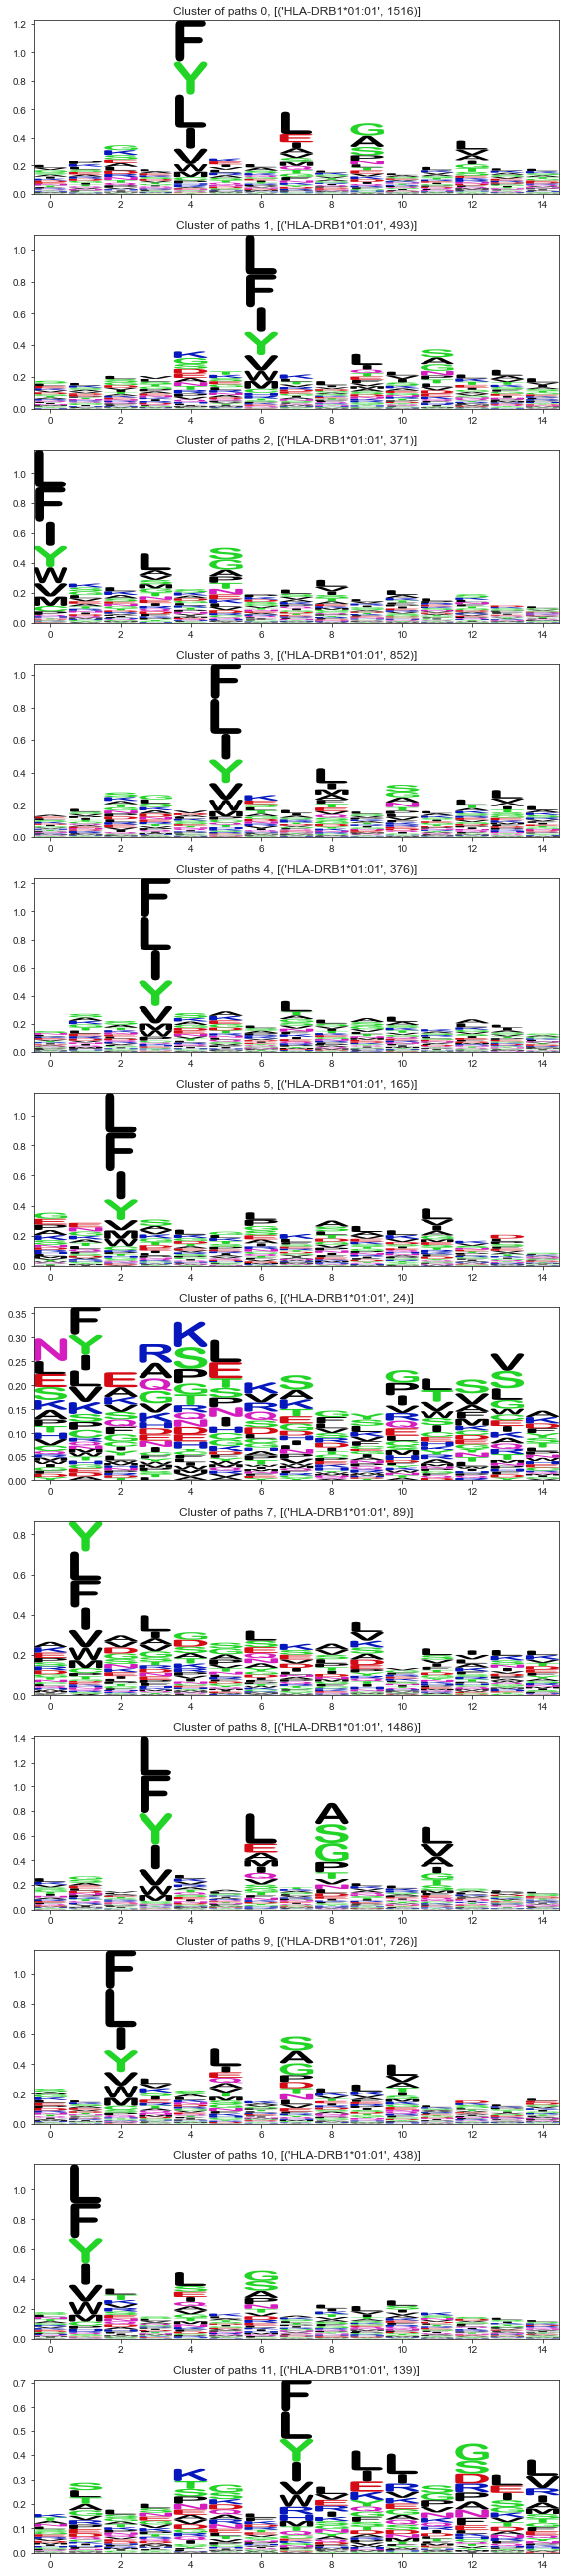

In [96]:

for target_length in TARGET_LENGTHS:
    fig, axes = plt.subplots(nrows=len(unique_labels_counts), figsize=(8, 3*len(unique_labels_counts)))
    for i, label in enumerate(sorted(unique_labels_counts.index)):
        target_label = f'path_gr_{label}'
        print(i)
        # filtered_df =  peptide_df.sort_values(by=f'path_gr_{label}', ascending=False)[:400]
        filtered_df =  peptide_df[peptide_df['max_label'] == target_label]
        filtered_df = filtered_df[filtered_df['len'] == target_length]
        # filtered_df =  filtered_df.sort_values(by=target_label, ascending=False)[:1000]
        counts = filtered_df['allele'].value_counts()


        matrix = logomaker.alignment_to_matrix(filtered_df['peptide'].values)
        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
        ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=axes[i])
        # counts_list = [(key, value) for key, value in sorted(counts.items())]
        counts = [(key, value) for key, value in sorted(counts.items())]
        ww_logo.ax.set_title(f"Cluster of paths {label}, {counts}")
    plt.tight_layout()


## Motif in data

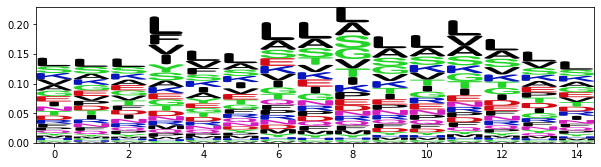

In [57]:
matrix = logomaker.alignment_to_matrix(peptides_df['peptide'].values)
info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')      
ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')

kk cluster 2

In [43]:
analysis_df = peptides_df[(peptides_df['leiden'] == '2') & (peptides_df['length'] == 10)]

In [44]:
len(analysis_df)

53

In [45]:
analysis_df.head(30)

,peptide,allele,length,leiden,louvain,immunogenic
16,LLYQGVYLKK,HLA-A*03:01,10,2,2,0
141,SLIGYLITKK,HLA-A*03:01,10,2,2,0
378,ILARWSSFKK,HLA-A*03:01,10,2,2,0
628,FLAQALSPKL,HLA-A*03:01,10,2,2,0
909,RLVQGSILKK,HLA-A*03:01,10,2,2,0
1028,ILKRWGQLKK,HLA-A*03:01,10,2,2,0
1055,TLYISECLKK,HLA-A*03:01,10,2,2,0
1184,KLFDFVNAKK,HLA-A*03:01,10,2,2,0
1234,QLCYCPASKK,HLA-A*03:01,10,2,2,0
1235,FLILCFTIKR,HLA-A*03:01,10,2,1,0


In [46]:
analysis_df['peptide'].str.contains('KK$').value_counts()

True     31
False    22
Name: peptide, dtype: int64

In [47]:
analysis_df['peptide'].str.contains('K[^K]$').value_counts()

False    37
True     16
Name: peptide, dtype: int64

In [48]:
analysis_df['peptide'].str.contains('[^K]K$').value_counts()

False    47
True      6
Name: peptide, dtype: int64

kkcluster 1

In [49]:
analysis_df = peptides_df[(peptides_df['leiden'] == '1') & (peptides_df['length'] == 10)]

In [50]:
len(analysis_df)

94

In [51]:
analysis_df['peptide'].str.contains('KK$').value_counts()

False    54
True     40
Name: peptide, dtype: int64

In [52]:
analysis_df['peptide'].str.contains('K[^K]$').value_counts()

False    56
True     38
Name: peptide, dtype: int64

In [53]:
analysis_df['peptide'].str.contains('[^K]K$').value_counts()

False    89
True      5
Name: peptide, dtype: int64

In [62]:
analysis_df.iloc[75:100][['peptide', 'length']]

,peptide,length
5393,KLLDEAIQAV,10
5482,LALEVARQKR,10
5489,RVKLPSGSKK,10
5700,KTIDASVSKK,10
5773,VVLGNIIKKK,10
5922,FVFPLNSKVK,10
5948,KSFPGIPLHH,10
5969,SLRTACVPHR,10
6081,ISWEALRWKA,10
6163,AQYQFTGIKK,10


In [63]:
test_df = analysis_df[~((analysis_df['peptide'].str.contains('[^K]K$')) | 
                         (analysis_df['peptide'].str.contains('K[^K]$')) |
                          (analysis_df['peptide'].str.contains('KK$')))
                         ]

In [64]:
test_df               

,peptide,allele,length,leiden,louvain,immunogenic
167,KLFPGSPAIY,HLA-A*03:01,10,1,1,0
1744,KIDKLTFQIY,HLA-A*03:01,10,1,1,0
2544,KTKDPTAALR,HLA-A*03:01,10,1,0,0
3240,GLLDSIKMIY,HLA-A*03:01,10,1,1,0
3951,LTDFGLSKIM,HLA-A*03:01,10,1,1,0
4159,KLSYGIATVR,HLA-A*03:01,10,1,1,0
4661,ILDDNLYKVY,HLA-A*03:01,10,1,1,0
4945,VTLAILTALR,HLA-A*03:01,10,1,1,0
5393,KLLDEAIQAV,HLA-A*03:01,10,1,1,0
5948,KSFPGIPLHH,HLA-A*03:01,10,1,1,0


In [95]:
target_df.loc['RLNDRYPKKL'].drop(labels=['allele', 'peptide']).astype(float).sort_values(ascending=False).head(20)

98     -0.318822
101    -0.342753
354    -0.368054
2927   -0.383446
2648   -0.384295
0      -0.384449
393    -0.389404
27     -0.394635
151    -0.401635
218    -0.409427
742    -0.410926
390    -0.411313
2858   -0.415922
2667   -0.417967
164    -0.418814
160    -0.421213
3988   -0.429674
135    -0.432491
317    -0.433329
3099   -0.433387
Name: RLNDRYPKKL, dtype: float64

In [66]:
target_df.loc['FLAQALSPKL'][98]

-0.5738168380742605

In [67]:
#0-th model
filename = 'D:\\Projects\\MHC_predictor\\experiments\\length_dependent_hmm\\experiment_results\\alleles_with_groups_single_allele_balanced_data\\0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_03_01-0\\viterbi_paths_df.csv'


In [68]:
df = pd.read_csv(filename, sep=';')

In [124]:
top500 = target_df.loc['RLNDRYPKKL'].drop(labels=['allele', 'peptide']).astype(float).sort_values(ascending=False).head(500).index

In [125]:
top500 = top500[top500.astype(int) < 500].astype(int)

In [126]:
top500

Int64Index([ 98, 101, 354,   0, 393,  27, 151, 218, 390, 164,
            ...
            406, 499, 105, 466, 385, 289, 439, 104, 492,  24],
           dtype='int64', length=143)

In [127]:
df

,path,prob,normalized_prob,len
0,grouped_model-start>s001>s004>s005>s008>s011>s...,-10.010188,-0.910017,9
1,grouped_model-start>s001>s004>s005>s014>s011>s...,-10.110780,-0.919162,9
2,grouped_model-start>s001>s003>s006>s008>s011>s...,-10.163696,-0.923972,9
3,grouped_model-start>s001>s004>s005>s007>s011>s...,-10.232188,-0.930199,9
4,grouped_model-start>s001>s004>s005>s007>s010>s...,-10.290974,-0.935543,9
...,...,...,...,...
708845,grouped_model-start>s003>s006>s014>s010>s014>s...,-32.849135,-2.986285,9
708846,grouped_model-start>s002>s007>s009>s014>s010>s...,-33.048400,-3.004400,9
708847,grouped_model-start>s002>s007>s014>s013>s011>s...,-33.216045,-3.019640,9
708848,grouped_model-start>s000>s008>s009>s006>s005>s...,-36.357856,-3.029821,10


In [129]:
df.loc[top500].len.value_counts()

9     126
10     17
Name: len, dtype: int64

In [76]:
df.loc[98]['path']

'grouped_model-start>s001>s004>s005>s008>s011>s010>s019>s015>s021>grouped_model-end'

In [79]:
df.loc[355]['path']

'grouped_model-start>s001>s004>s005>s014>s010>s012>s016>s019>s021>grouped_model-end'

In [80]:
df['path'][0]

'grouped_model-start>s001>s004>s005>s008>s011>s016>s019>s015>s021>grouped_model-end'

In [81]:
df['path'][:500].str.contains('s021>grouped_model-end').value_counts()

True    500
Name: path, dtype: int64

In [90]:
df['path'].str.contains('s021>grouped_model-end').value_counts()

False    496474
True     212376
Name: path, dtype: int64

In [86]:
df[:500]['len'].value_counts()

9     331
10    169
Name: len, dtype: int64

In [85]:
df.head(50)

,path,prob,normalized_prob,len
0,grouped_model-start>s001>s004>s005>s008>s011>s...,-10.010188,-0.910017,9
1,grouped_model-start>s001>s004>s005>s014>s011>s...,-10.110780,-0.919162,9
2,grouped_model-start>s001>s003>s006>s008>s011>s...,-10.163696,-0.923972,9
3,grouped_model-start>s001>s004>s005>s007>s011>s...,-10.232188,-0.930199,9
4,grouped_model-start>s001>s004>s005>s007>s010>s...,-10.290974,-0.935543,9
5,grouped_model-start>s001>s003>s009>s008>s011>s...,-10.295797,-0.935982,9
6,grouped_model-start>s001>s003>s006>s010>s019>s...,-10.385203,-0.944109,9
7,grouped_model-start>s001>s004>s006>s008>s011>s...,-10.401353,-0.945578,9
8,grouped_model-start>s001>s003>s006>s010>s012>s...,-10.419387,-0.947217,9
9,grouped_model-start>s001>s003>s006>s010>s016>s...,-11.375047,-0.947921,10


In [91]:
no_anchor_at_the_end = df[~df['path'].str.contains('s021>grouped_model-end')]

In [92]:
no_anchor_at_the_end

,path,prob,normalized_prob,len
770,grouped_model-start>s001>s004>s005>s008>s011>s...,-11.619110,-1.056283,9
972,grouped_model-start>s001>s004>s005>s014>s011>s...,-11.719701,-1.065427,9
1069,grouped_model-start>s001>s003>s006>s008>s011>s...,-11.772617,-1.070238,9
1258,grouped_model-start>s001>s004>s005>s007>s011>s...,-11.841109,-1.076464,9
1336,grouped_model-start>s001>s003>s008>s011>s016>s...,-12.953968,-1.079497,10
...,...,...,...,...
708845,grouped_model-start>s003>s006>s014>s010>s014>s...,-32.849135,-2.986285,9
708846,grouped_model-start>s002>s007>s009>s014>s010>s...,-33.048400,-3.004400,9
708847,grouped_model-start>s002>s007>s014>s013>s011>s...,-33.216045,-3.019640,9
708848,grouped_model-start>s000>s008>s009>s006>s005>s...,-36.357856,-3.029821,10


In [193]:
no_anchor_at_the_end.loc[770].path

'grouped_model-start>s001>s004>s005>s008>s011>s016>s019>s015>s024>grouped_model-end'

In [194]:
no_anchor_at_the_end.loc[972].path

'grouped_model-start>s001>s004>s005>s014>s011>s016>s019>s015>s024>grouped_model-end'

In [195]:
no_anchor_at_the_end.loc[1069].path

'grouped_model-start>s001>s003>s006>s008>s011>s016>s019>s015>s024>grouped_model-end'

In [93]:
no_anchor_at_the_end.loc[1258].path

'grouped_model-start>s001>s004>s005>s007>s011>s016>s019>s015>s024>grouped_model-end'

## Motif for 10 mers

In [247]:
df = peptides_df[peptides_df['length'] == 11]
make_logo(df,length=10, cluster_num=0)

In [310]:
peptides_df[peptides_df['peptide'].str.contains("K[^K]$")]

,peptide,allele,length,leiden,louvain,immunogenic
104,RLKGPLLNKR,HLA-A*03:01,10,5,2,0
122,KTSDVVLKR,HLA-A*03:01,9,3,0,0
139,LALEGSLQKR,HLA-A*03:01,10,1,1,0
178,IQNVPLSEKI,HLA-A*03:01,10,1,1,0
269,KSMRDQRKG,HLA-A*03:01,9,0,0,0
...,...,...,...,...,...,...
6113,TVYPVAIKY,HLA-A*03:01,9,0,0,0
6309,RIFVYFITKL,HLA-A*03:01,10,1,1,0
6313,KLYKNKSKQ,HLA-A*03:01,9,4,0,0
6475,VVFGILIKR,HLA-A*03:01,9,0,0,0


### Select metric

In [172]:
metrics = [  'sokalmichener', 'sokalsneath', 'yule', 'cosine', 'euclidean', 'l1', 'l2', 'manhattan','braycurtis', 'canberra', 'chebyshev', 'correlation', 'dice', 'hamming', 'jaccard', 'kulsinski', 'mahalanobis', 'minkowski', 'rogerstanimoto', 'russellrao']

metric: sokalmichener (0, 0)
metric: sokalsneath (0, 1)
metric: yule (0, 2)
metric: cosine (0, 3)
metric: euclidean (0, 4)
metric: l1 (1, 0)
metric: l2 (1, 1)
metric: manhattan (1, 2)
metric: braycurtis (1, 3)
metric: canberra (1, 4)
metric: chebyshev (2, 0)
metric: correlation (2, 1)
metric: dice (2, 2)
metric: hamming (2, 3)
metric: jaccard (2, 4)
metric: kulsinski (3, 0)
metric: mahalanobis (3, 1)
metric: minkowski (3, 2)
metric: rogerstanimoto (3, 3)
metric: russellrao (3, 4)


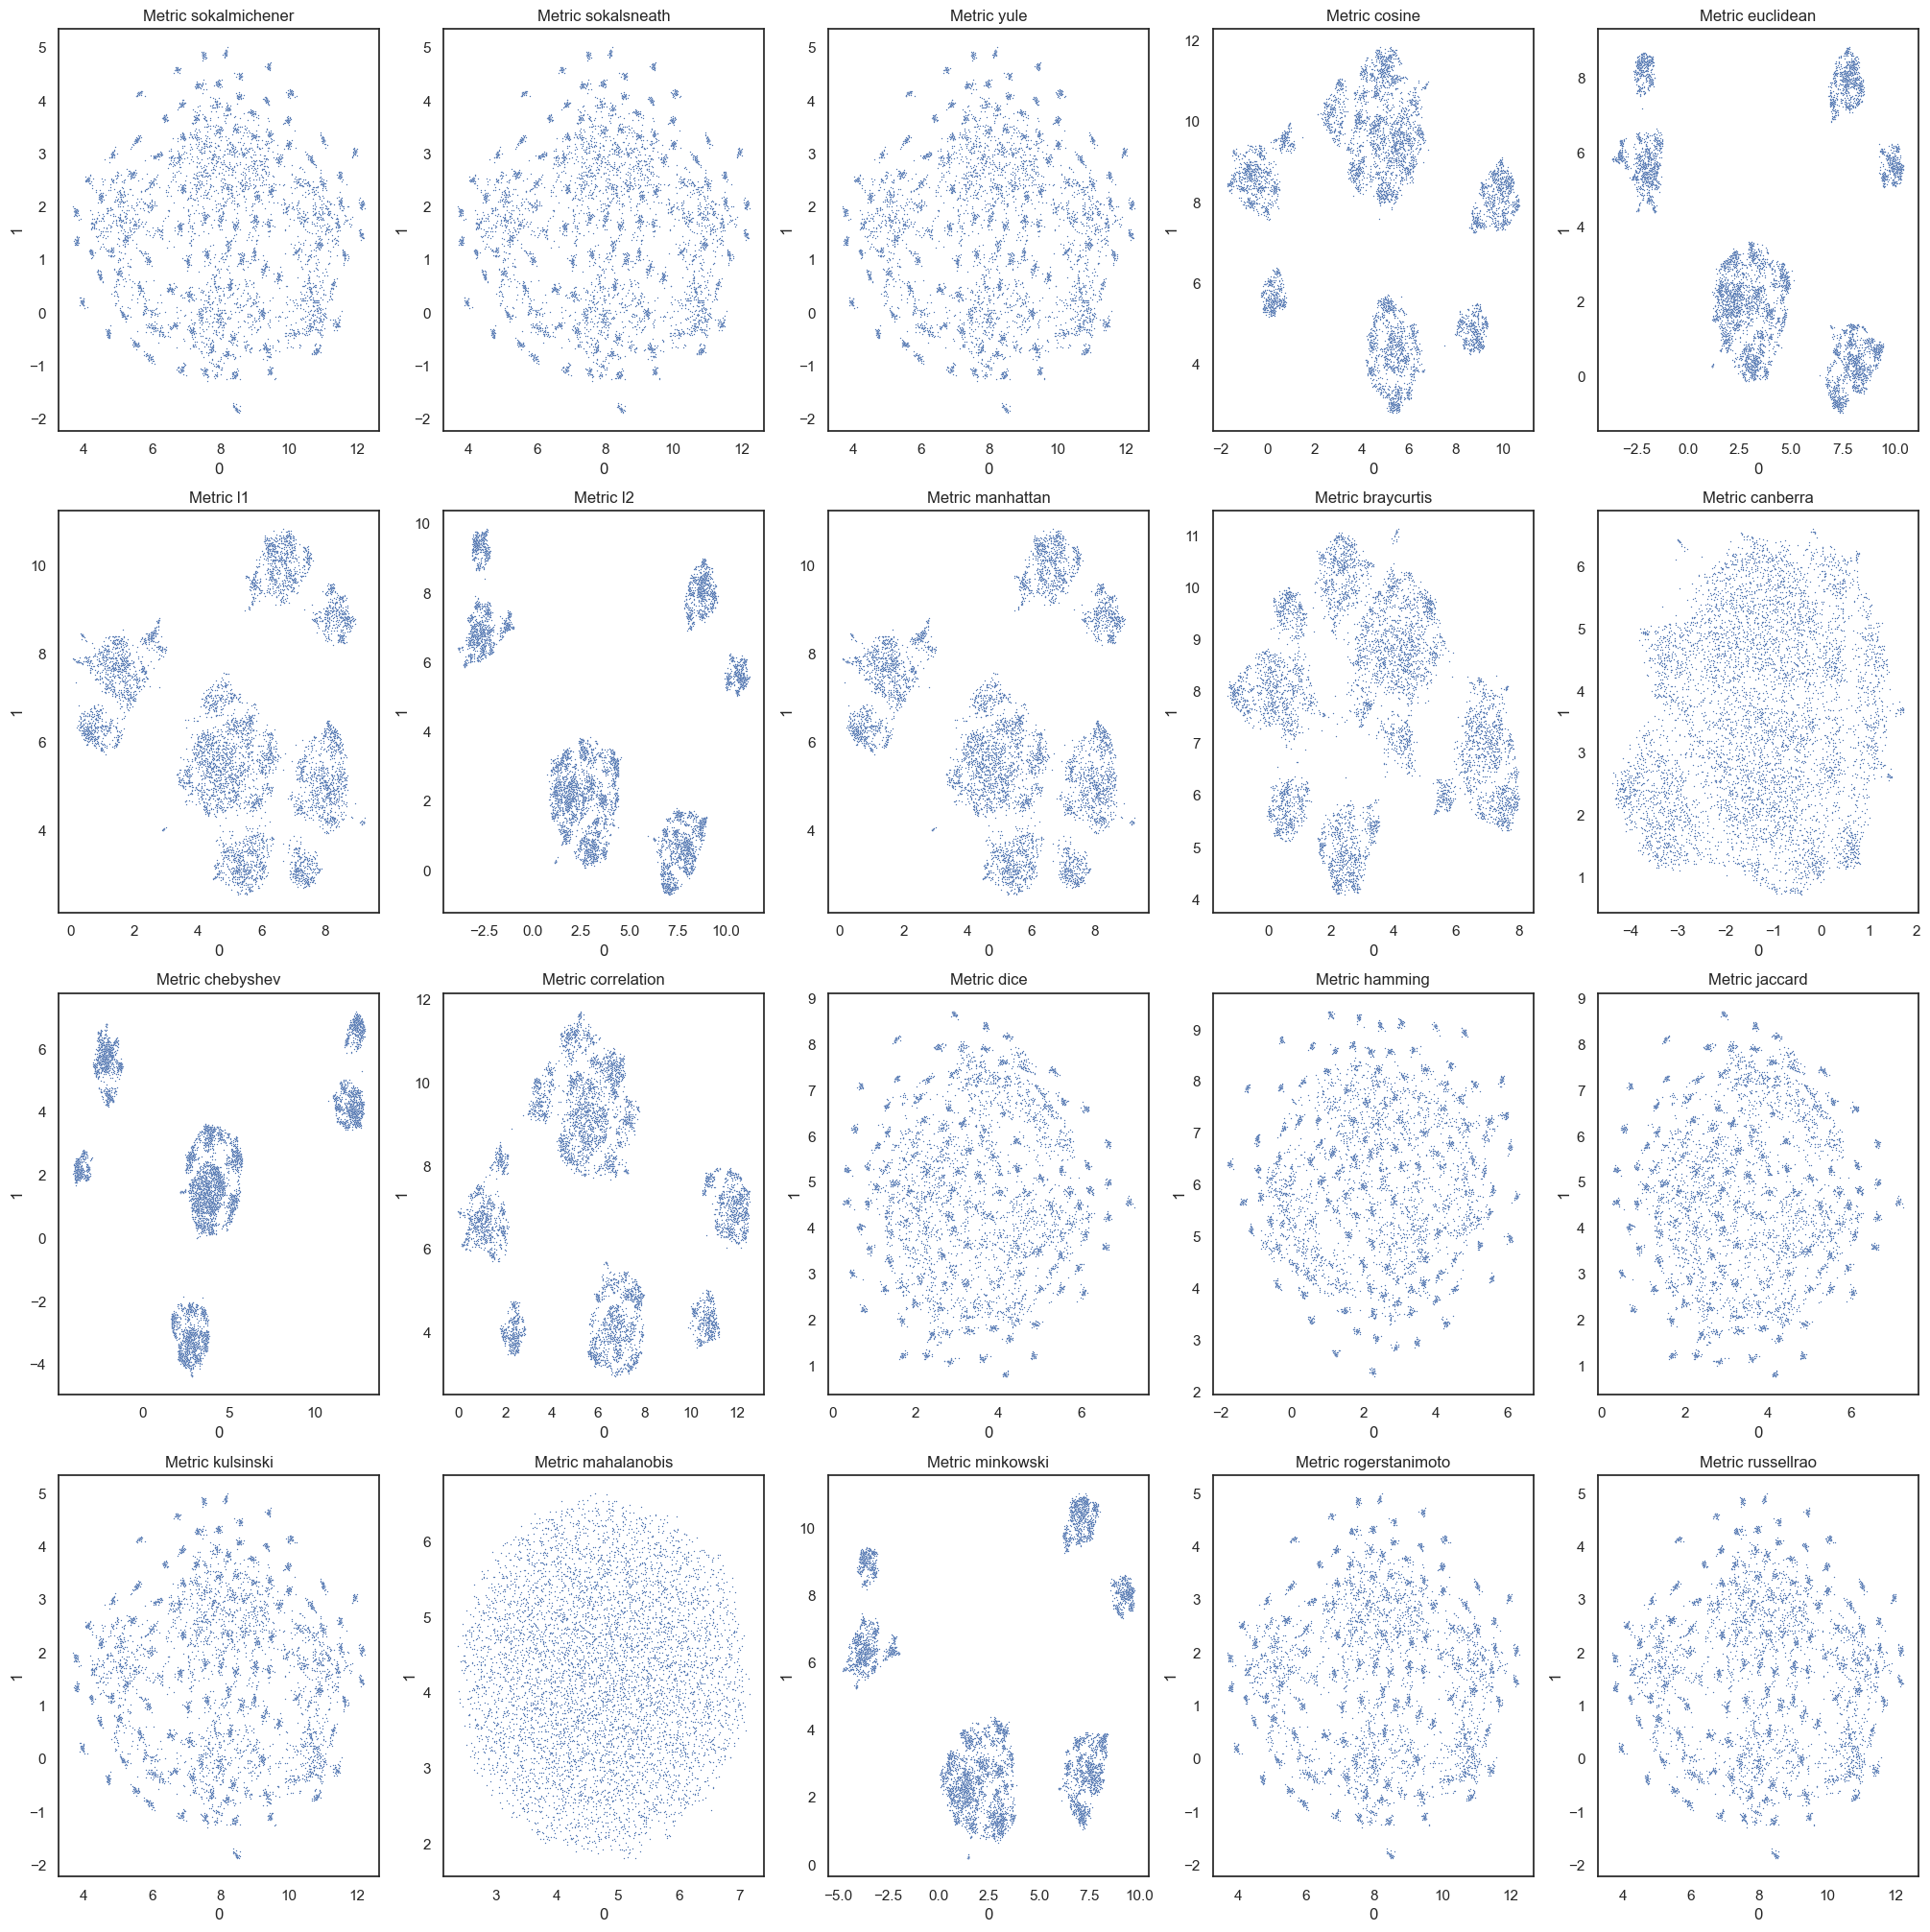

In [173]:
fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(25,25))
for coord, metric in zip(product(range(5), range(5)), metrics):
    print("metric:", metric , coord)
    sc.pp.neighbors(adata, n_neighbors=50, n_pcs=30, metric=metric)
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"Metric {metric}")

### Select number of principal components

In [120]:
principal_components = range(5, 30, 5)

In [121]:
list(principal_components)

[5, 10, 15, 20, 25]

In [122]:
len(list(principal_components))

5

n_pcs: 5
n_pcs: 10
n_pcs: 15
n_pcs: 20
n_pcs: 25


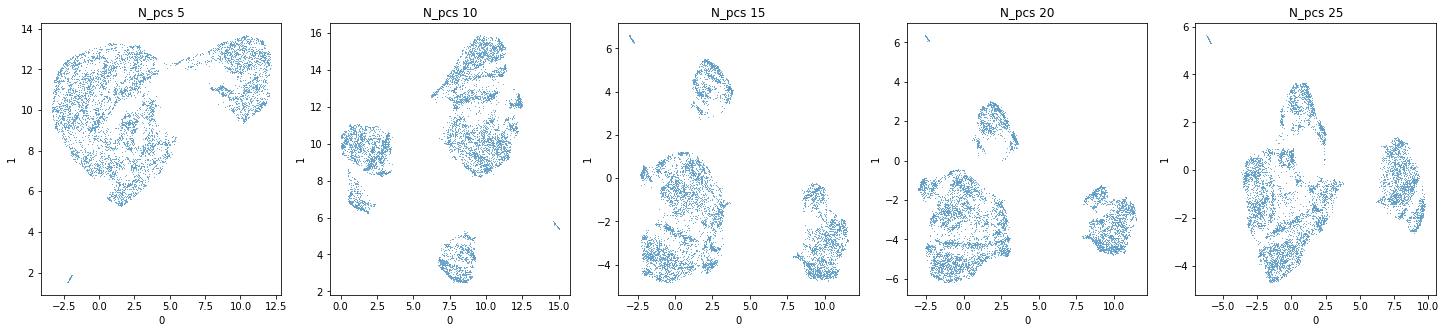

In [123]:
fig, axes = plt.subplots(ncols=5, figsize=(25,5))
for i, n_pcs in enumerate(principal_components):
    print("n_pcs:", n_pcs)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=n_pcs, metric='euclidean')
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[i]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"N_pcs {n_pcs}")

### Select number of neighbours

In [59]:
num_neighbors = range(5, 55, 5)

In [60]:
len(num_neighbors)

10

n_neighbors: 5 (0, 0)
n_neighbors: 10 (0, 1)
n_neighbors: 15 (0, 2)
n_neighbors: 20 (0, 3)
n_neighbors: 25 (0, 4)
n_neighbors: 30 (1, 0)
n_neighbors: 35 (1, 1)
n_neighbors: 40 (1, 2)
n_neighbors: 45 (1, 3)
n_neighbors: 50 (1, 4)


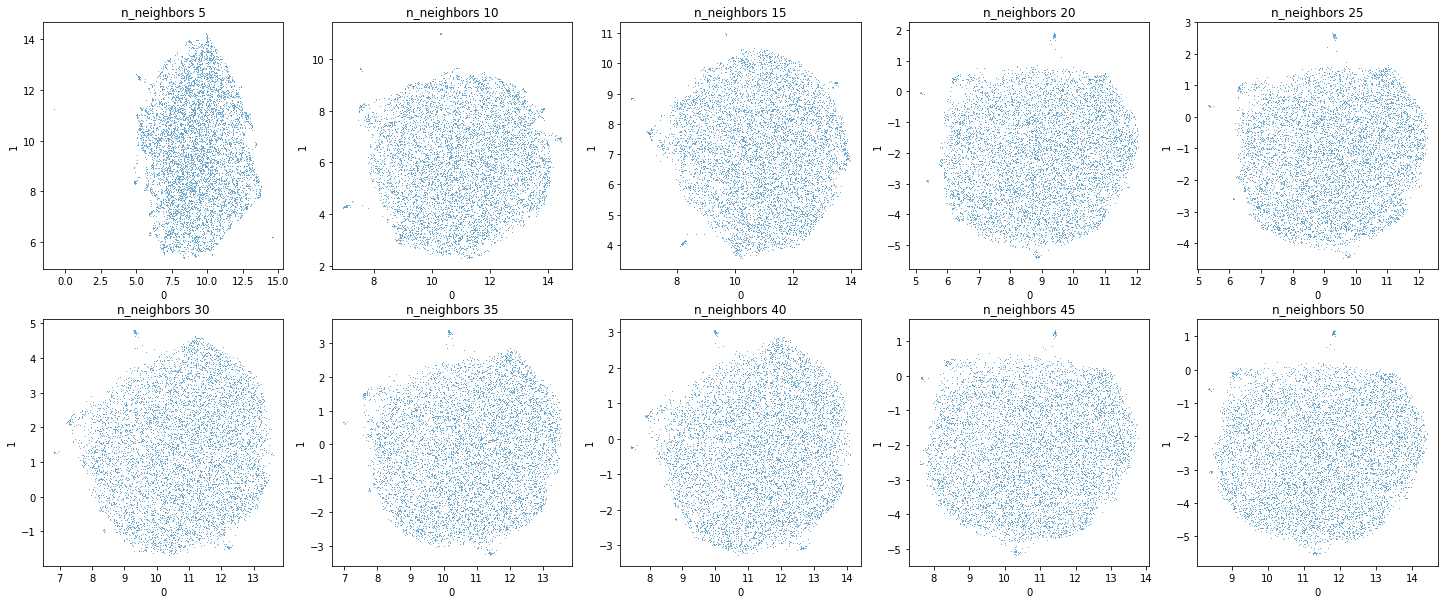

In [61]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(25,10))
for coord, n_neighbors in zip(product(range(2), range(5)), num_neighbors):
    print("n_neighbors:", n_neighbors , coord)
    sc.pp.neighbors(adata, n_neighbors=n_neighbors, n_pcs=15, metric='euclidean')
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"n_neighbors {n_neighbors}")


### Select min_dist

In [159]:
min_dists = np.linspace(0.05, 0.5, 10)

min_dist: 0.05 (0, 0)
min_dist: 0.1 (0, 1)
min_dist: 0.15000000000000002 (0, 2)
min_dist: 0.2 (0, 3)
min_dist: 0.25 (0, 4)
min_dist: 0.3 (1, 0)
min_dist: 0.35000000000000003 (1, 1)
min_dist: 0.4 (1, 2)
min_dist: 0.45 (1, 3)
min_dist: 0.5 (1, 4)


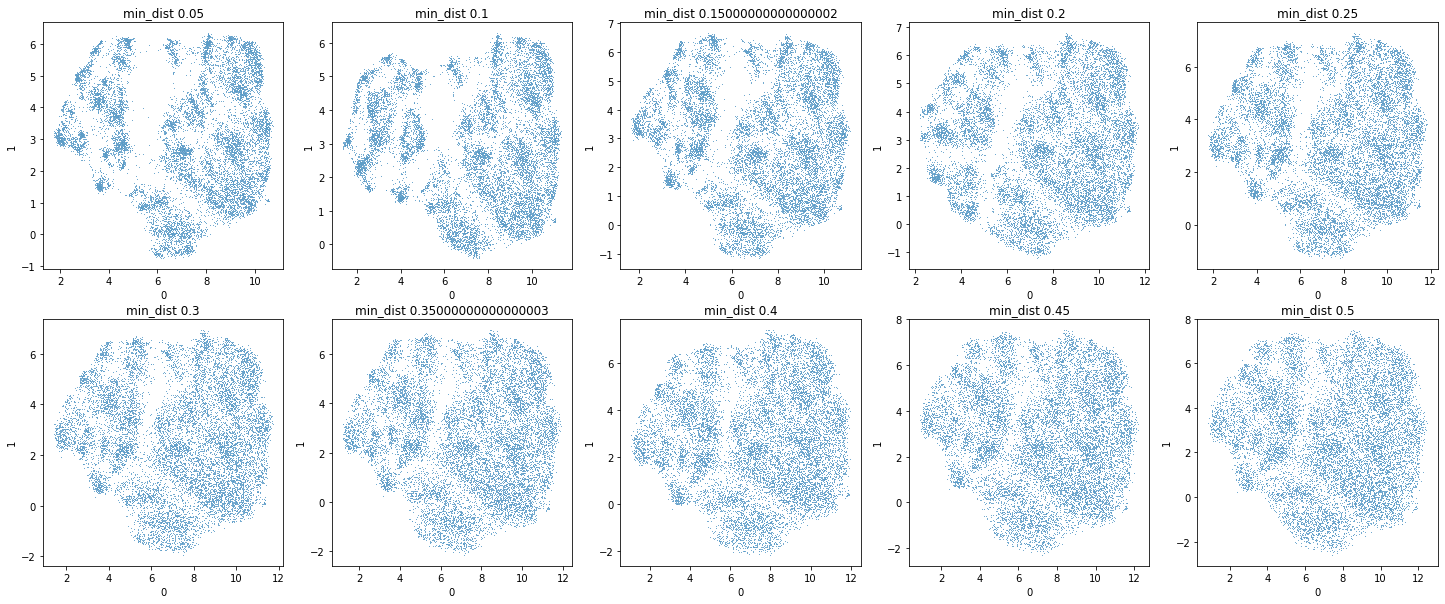

In [160]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(25,10))
for coord, min_dist in zip(product(range(2), range(5)), min_dists):
    print("min_dist:", min_dist , coord)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, metric='euclidean')
    sc.tl.umap(adata, min_dist=min_dist)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"min_dist {min_dist}")